In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sb
import kagglehub
from scipy.stats import uniform, randint
# from google.colab import drive
# Evaluation tools
import time
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, cross_val_score, learning_curve, RandomizedSearchCV, train_test_split
from sklearn.preprocessing import label_binarize, StandardScaler, LabelEncoder, MinMaxScaler
# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

**Download Dataset**
##### https://www.kaggle.com/datasets/whenamancodes/student-performance/data (link to dataset)

In [9]:
path = kagglehub.dataset_download("whenamancodes/student-performance")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Windows10\.cache\kagglehub\datasets\whenamancodes\student-performance\versions\2


In [10]:
#Copy dataset to drive for easier access
#drive.mount('/content/drive')
#!cp -r /kaggle/input/student-performance /content/drive/MyDrive/

In [13]:
#Show files
!ls /kaggle/input/student-performance
!file /kaggle/input/student-performance/Maths.csv


'ls' is not recognized as an internal or external command,
operable program or batch file.
'file' is not recognized as an internal or external command,
operable program or batch file.


In [15]:
# Read file
pkmdf = pd.read_excel(os.path.join(path, 'Maths.csv'))
pkmdf.head(5)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [16]:
pkmdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      397 non-null    object
 1   sex         397 non-null    object
 2   age         397 non-null    int64 
 3   address     397 non-null    object
 4   famsize     397 non-null    object
 5   Pstatus     397 non-null    object
 6   Medu        397 non-null    int64 
 7   Fedu        397 non-null    int64 
 8   Mjob        397 non-null    object
 9   Fjob        397 non-null    object
 10  reason      397 non-null    object
 11  guardian    397 non-null    object
 12  traveltime  397 non-null    int64 
 13  studytime   397 non-null    int64 
 14  failures    397 non-null    int64 
 15  schoolsup   397 non-null    object
 16  famsup      397 non-null    object
 17  paid        397 non-null    object
 18  activities  397 non-null    object
 19  nursery     397 non-null    object
 20  higher    

**Handle Missing Value and Deduplicate Data**

In [20]:
pkmdf.isnull().sum() # handle missing value

pkmdf.duplicated().sum() # check duplicate data
pkmdf.drop_duplicates(inplace=True) # deduplicate
pkmdf.duplicated().sum() # check again

0

**Discretize G3 to Pass/Fail**


In [23]:
# 8 as passing grade (8/20=40%)
threshold = 8
pkmdf['PassFail'] = pkmdf['G3'].apply(lambda x: 'Pass' if x >= threshold else 'Fail')
pkmdf['PassFail_bin'] = pkmdf['PassFail'].map({'Fail': 1, 'Pass': 0})

print(pkmdf['PassFail'].value_counts())

PassFail
Pass    325
Fail     70
Name: count, dtype: int64


In [25]:
pkmdf=pkmdf.drop(columns=['G3', 'PassFail'])

In [27]:
# Separate Data into Features and Label(G3)
features = pkmdf.drop(columns=['PassFail_bin'])
label = pkmdf['PassFail_bin']

# Define numeric columns for later use
numeric_cols = ['age','Medu','Fedu','traveltime','studytime','failures','famrel','freetime','goout','Dalc','Walc','health','absences','G1','G2']
cat_cols = [col for col in features.columns if col not in numeric_cols] #binary+nominal
nominal_cols = ["Mjob", "Fjob", "reason", "guardian"]
binary_cols = [col for col in cat_cols if col not in nominal_cols]

In [29]:
binary_cols

['school',
 'sex',
 'address',
 'famsize',
 'Pstatus',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic']

**EDA**


*   Statistical Summary
*   Graph Plotting
*   Pair Plot
*   Correlation Heat Map
*   Cluster Map








In [32]:
# Descriptive Statistics of numerical features
pkmdf.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,PassFail_bin
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,0.177215
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,0.382335
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,0.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,0.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,0.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,1.000000


In [34]:
# Descriptive Statistics for categorical features
pkmdf.describe(include='object')

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
count,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395,395
unique,2,2,2,2,2,5,5,4,3,2,2,2,2,2,2,2,2
top,GP,F,U,GT3,T,other,other,course,mother,no,yes,no,yes,yes,yes,yes,no
freq,349,208,307,281,354,141,217,145,273,344,242,214,201,314,375,329,263


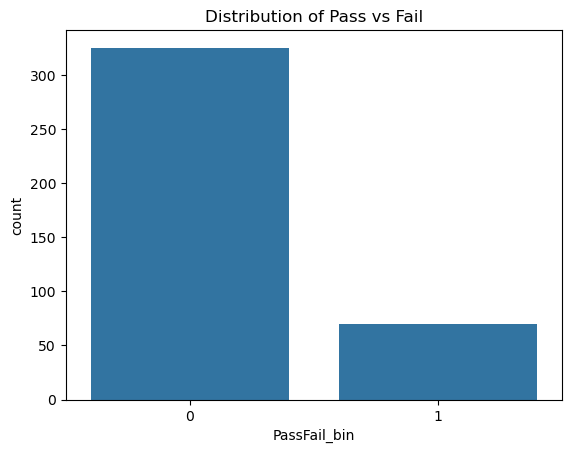

In [36]:
# Countplot for Label (PassFail_bin) Distribution to show class balance
sb.countplot(x='PassFail_bin', data=pkmdf)
plt.title('Distribution of Pass vs Fail')
plt.show()

In [38]:
# Numerical Features Plot: Histogram + Boxplot
def plot_numeric_features(df, target='PassFail_bin'):
    for col in numeric_cols:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        # histogram
        sb.histplot(df[col], kde=True, ax=axes[0], color='skyblue')
        axes[0].set_title(f'Distribution of {col}')
        # boxplot
        sb.boxplot(x=target, y=col, hue=target, data=df, ax=axes[1], palette='Set3')
        axes[1].set_title(f'{col} vs {target}')
        plt.show()

# Boolean & Nominal Feature Plot: Countplot + Boxplot
def plot_binarynominal_features(df, target='PassFail_bin'):
    for col in cat_cols:
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        # countplot
        sb.countplot(x=col, hue=target, data=df, ax=axes[0], palette='Set2')
        axes[0].set_title(f'{col} by {target}')
        # barplot
        fail_rate = df.groupby(col)['PassFail_bin'].mean().reset_index()
        sb.barplot(x=col, y='PassFail_bin', hue=col, data=fail_rate, palette='Set3')
        axes[1].set_title(f'Fail Rate by {col}')
        axes[1].set_ylabel('Fail Rate (0–1)')
        plt.show()


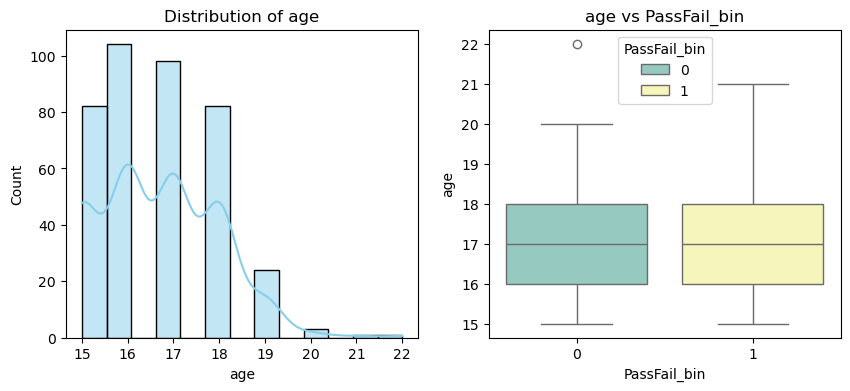

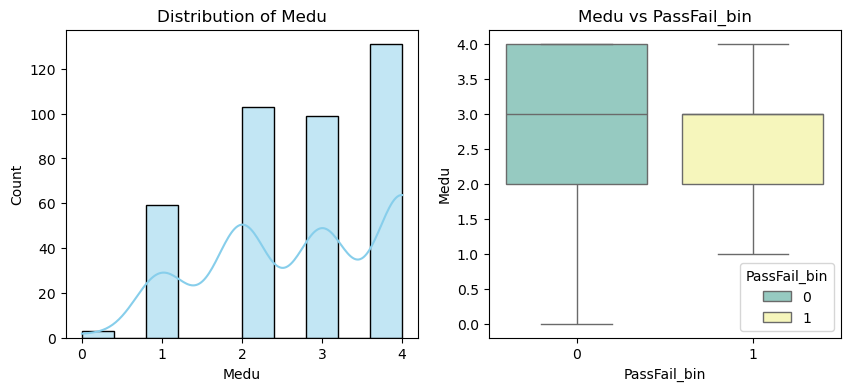

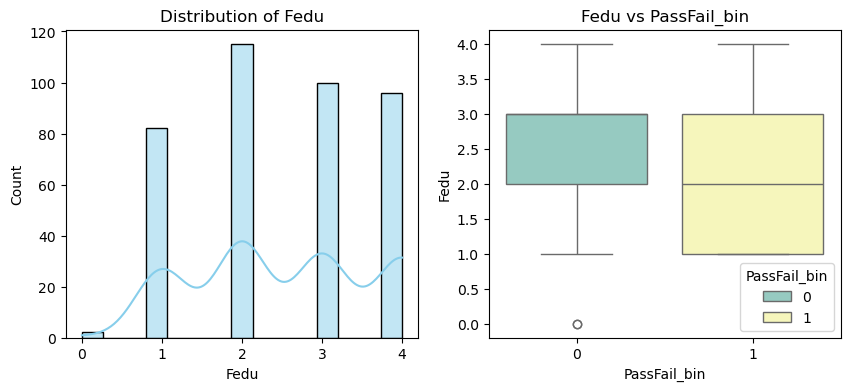

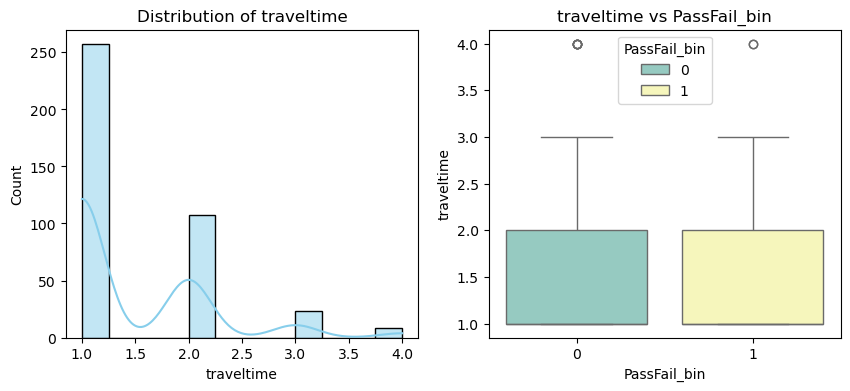

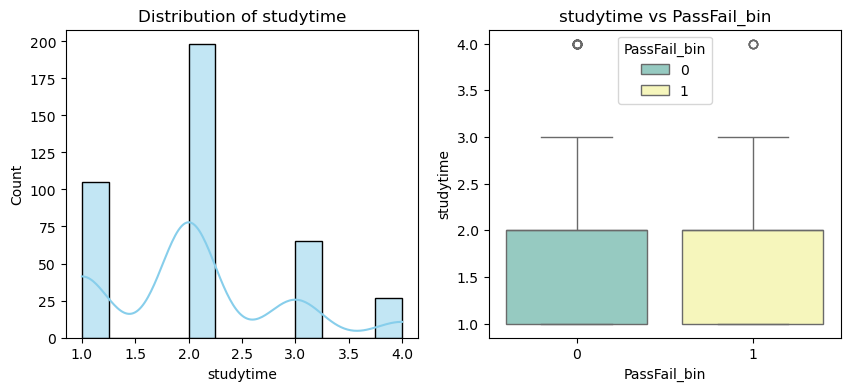

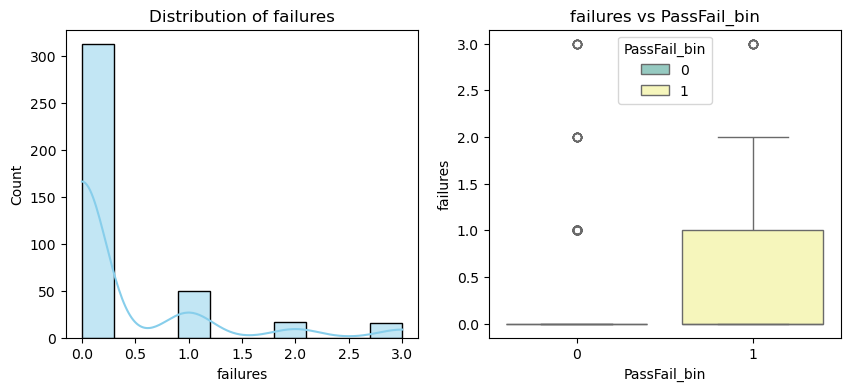

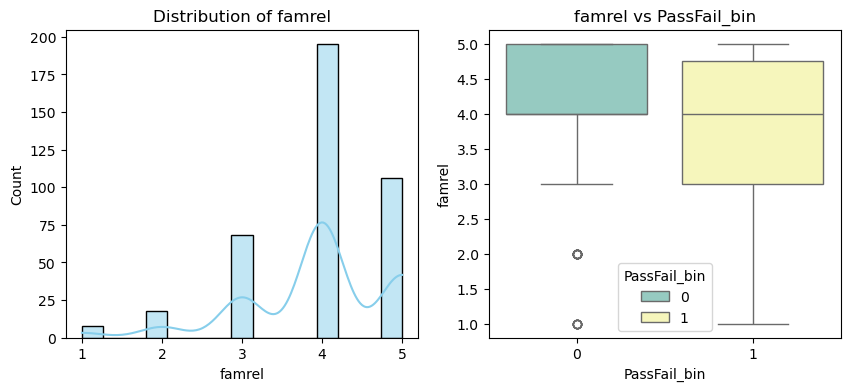

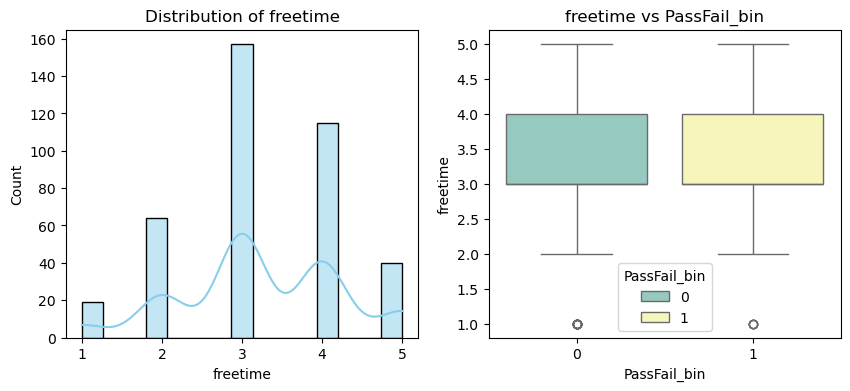

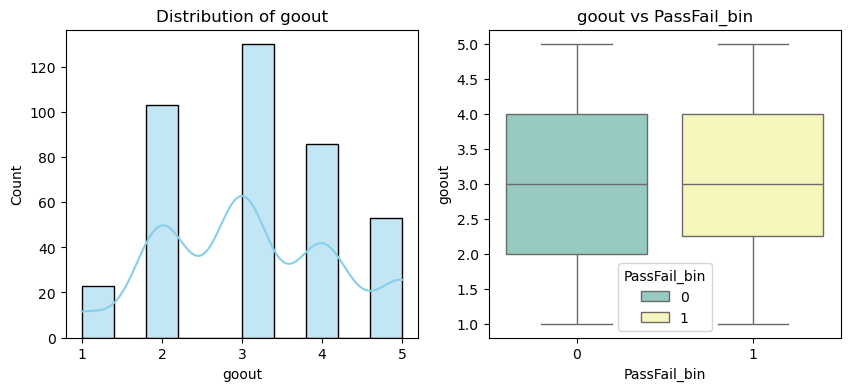

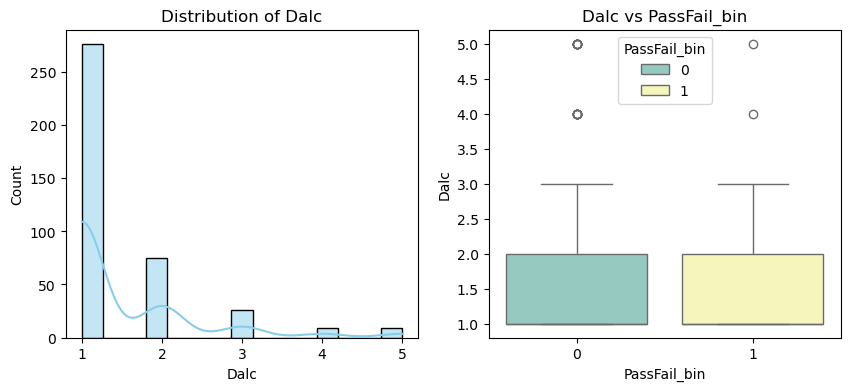

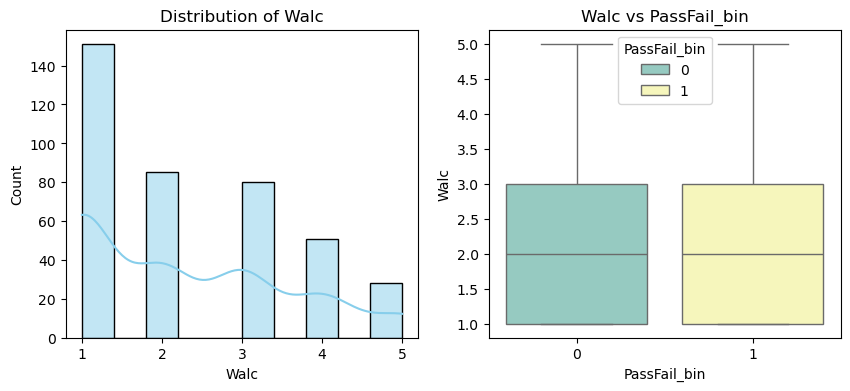

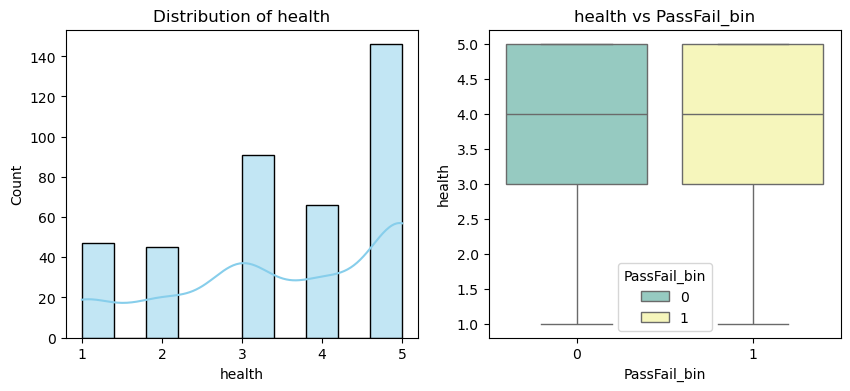

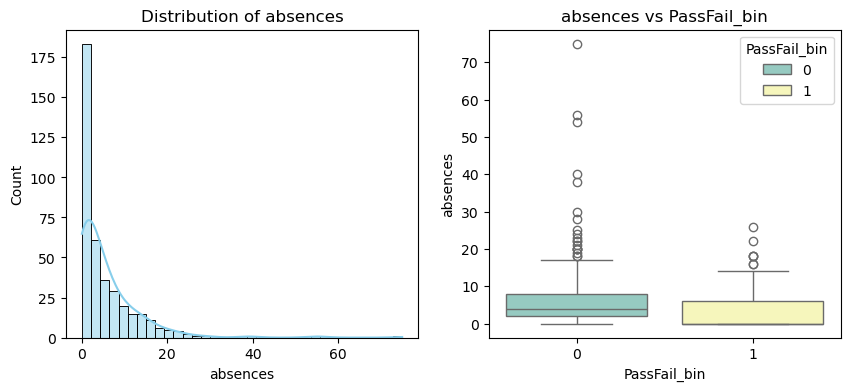

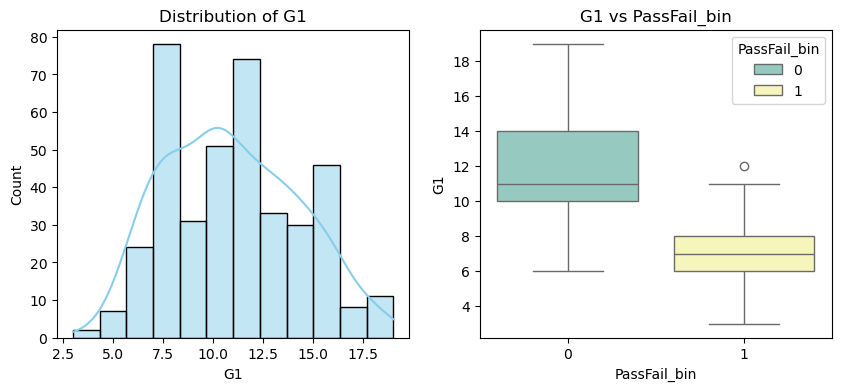

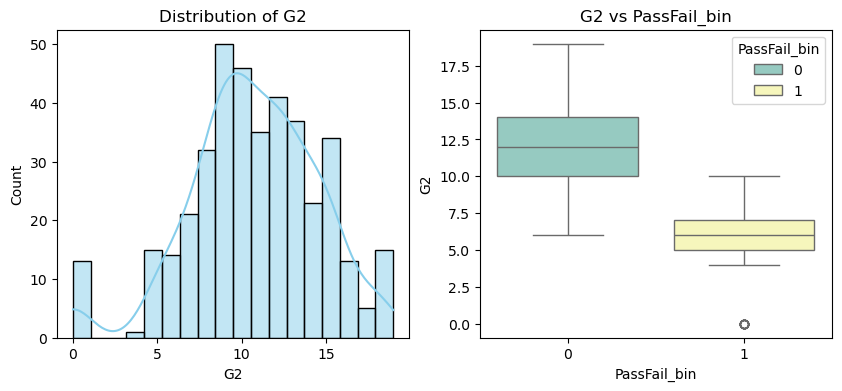

In [40]:
plot_numeric_features(pkmdf)

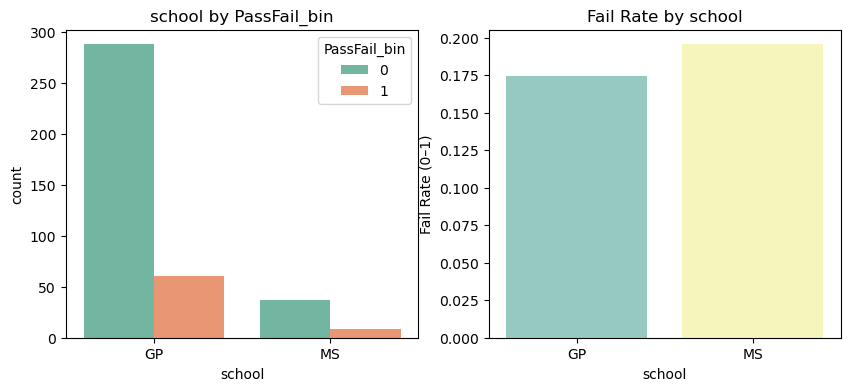

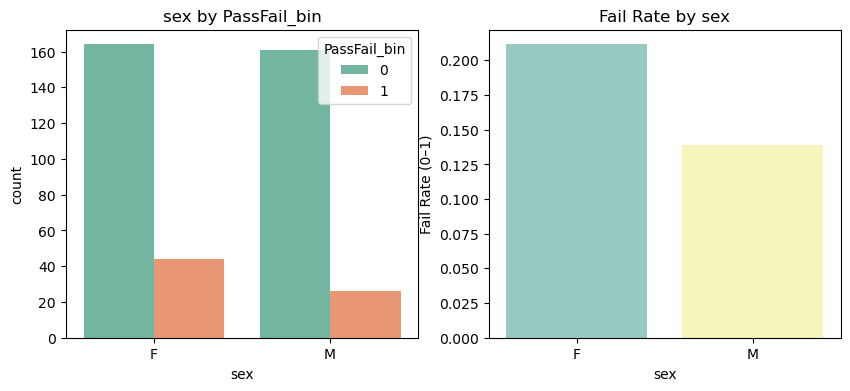

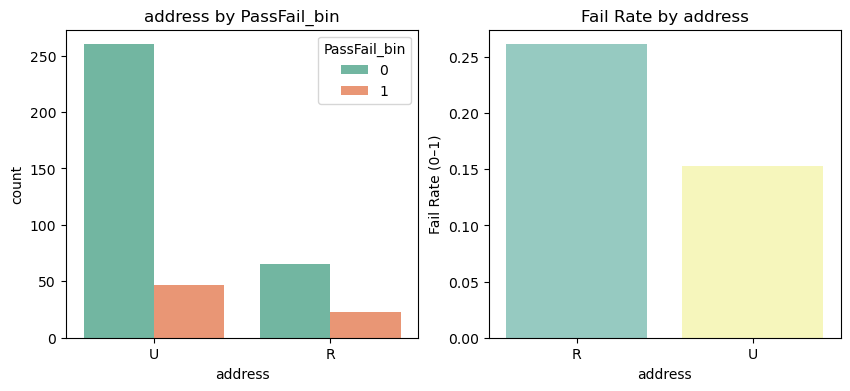

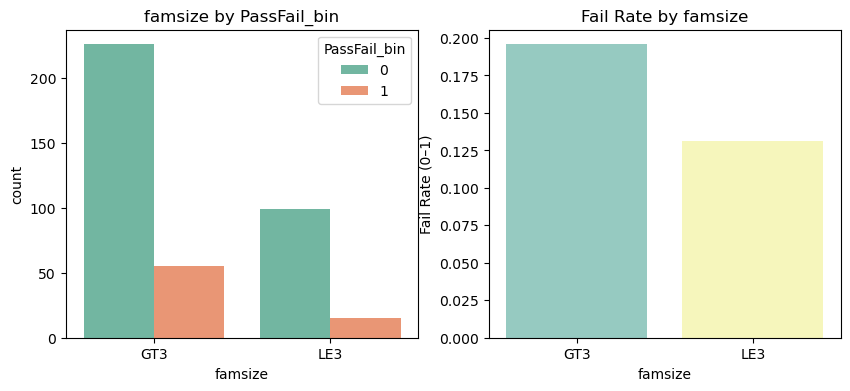

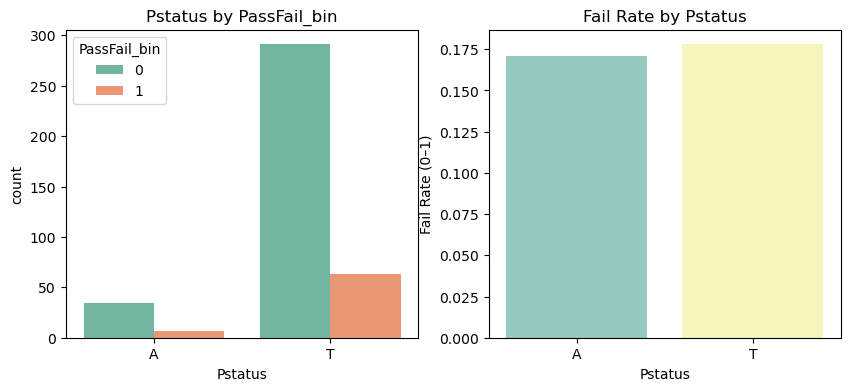

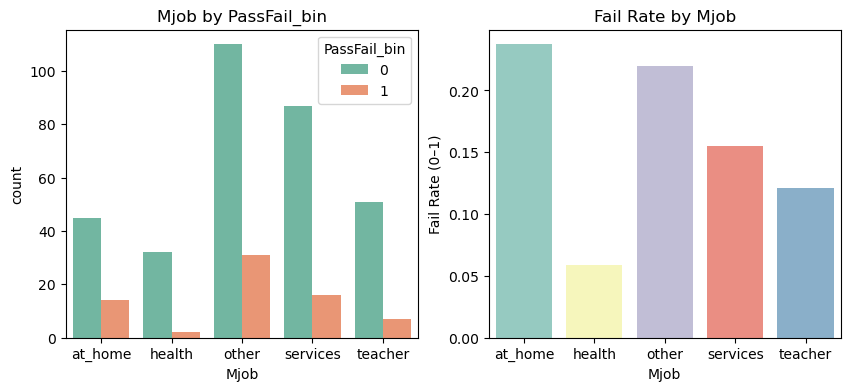

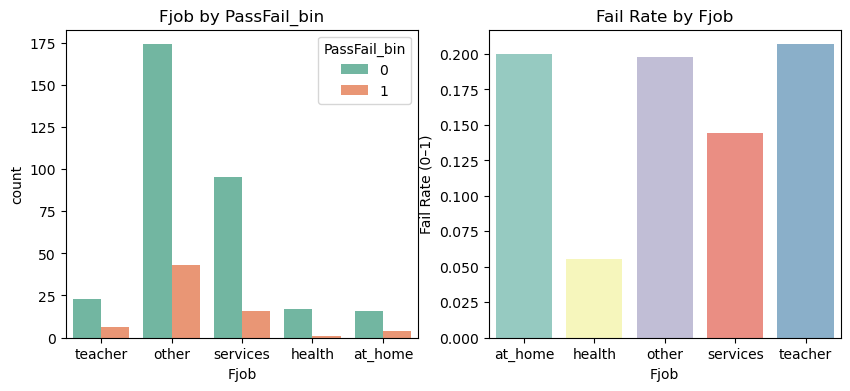

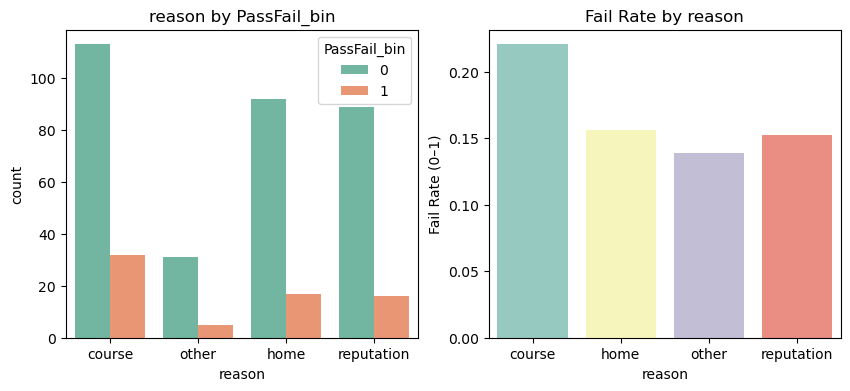

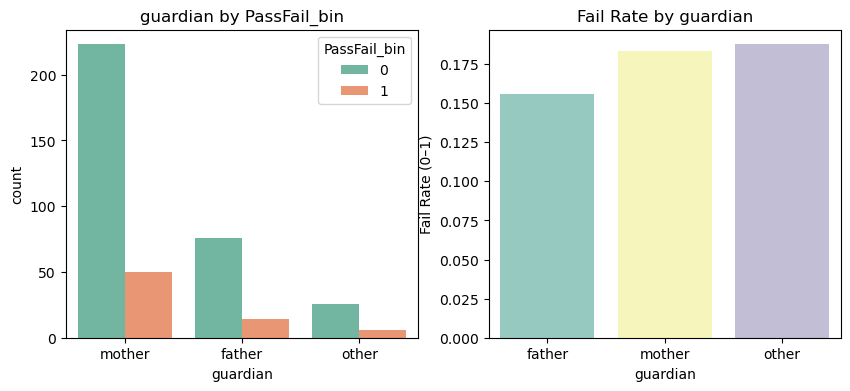

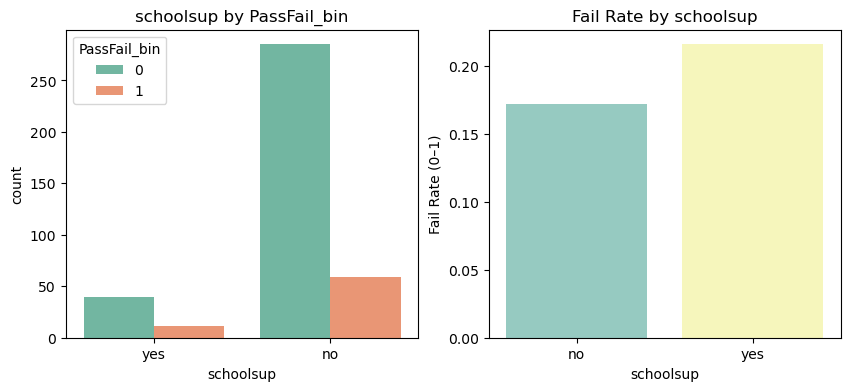

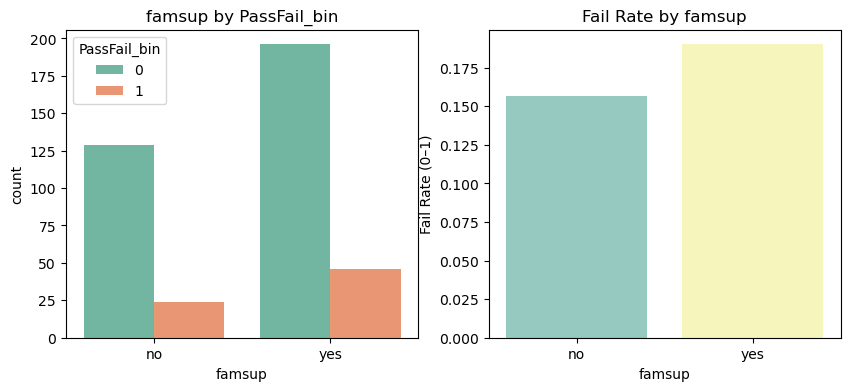

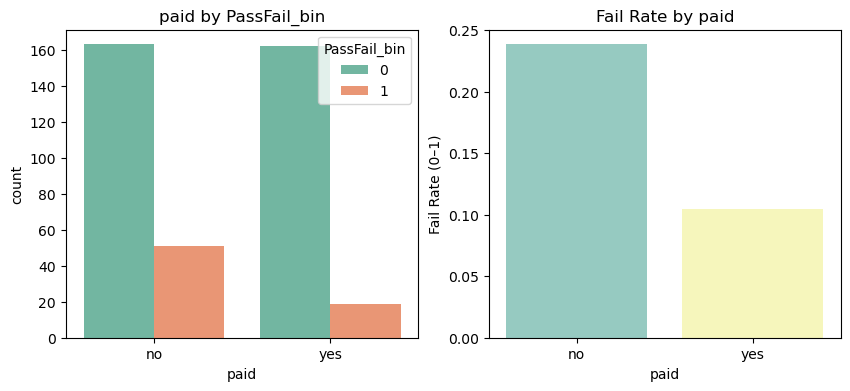

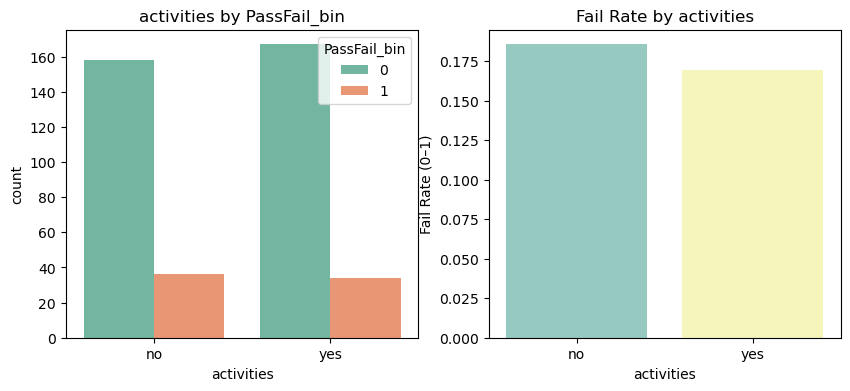

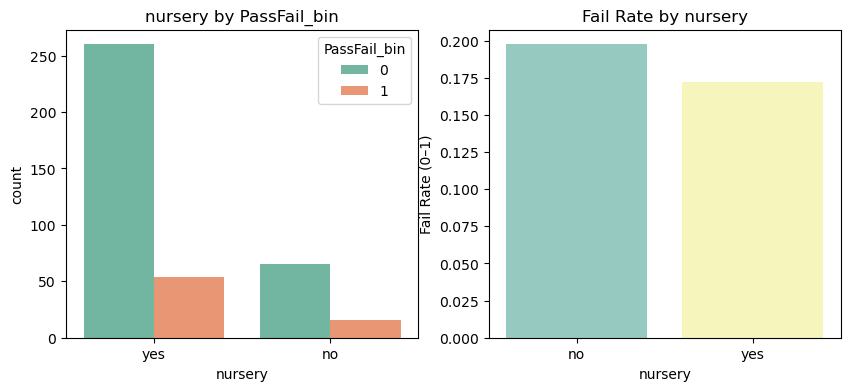

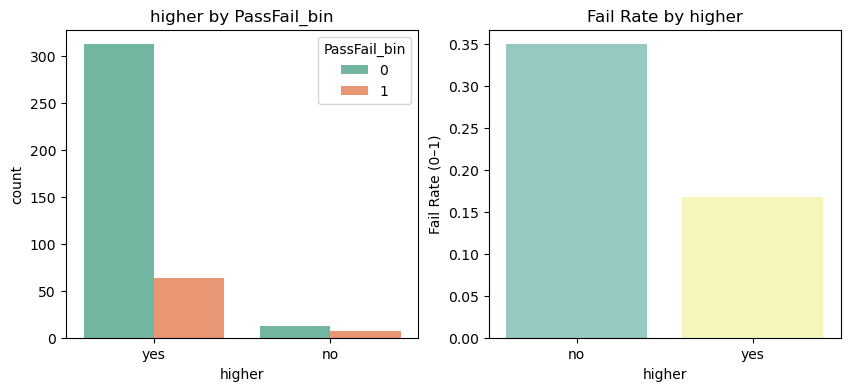

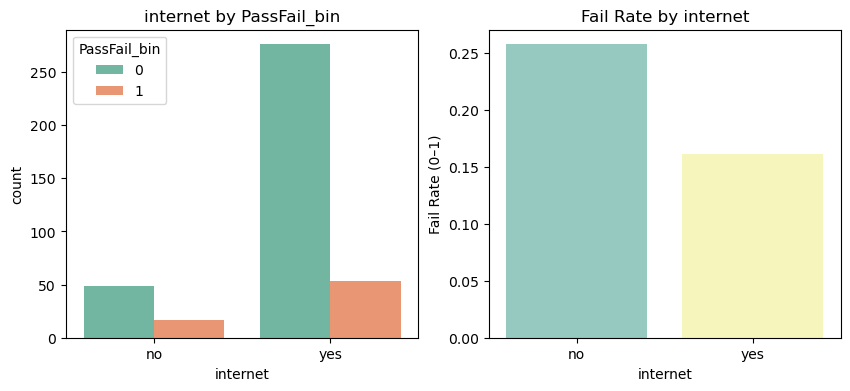

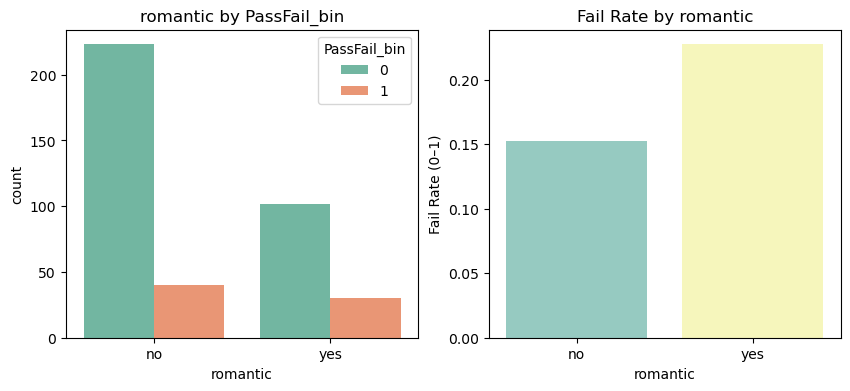

In [41]:
plot_binarynominal_features(pkmdf)

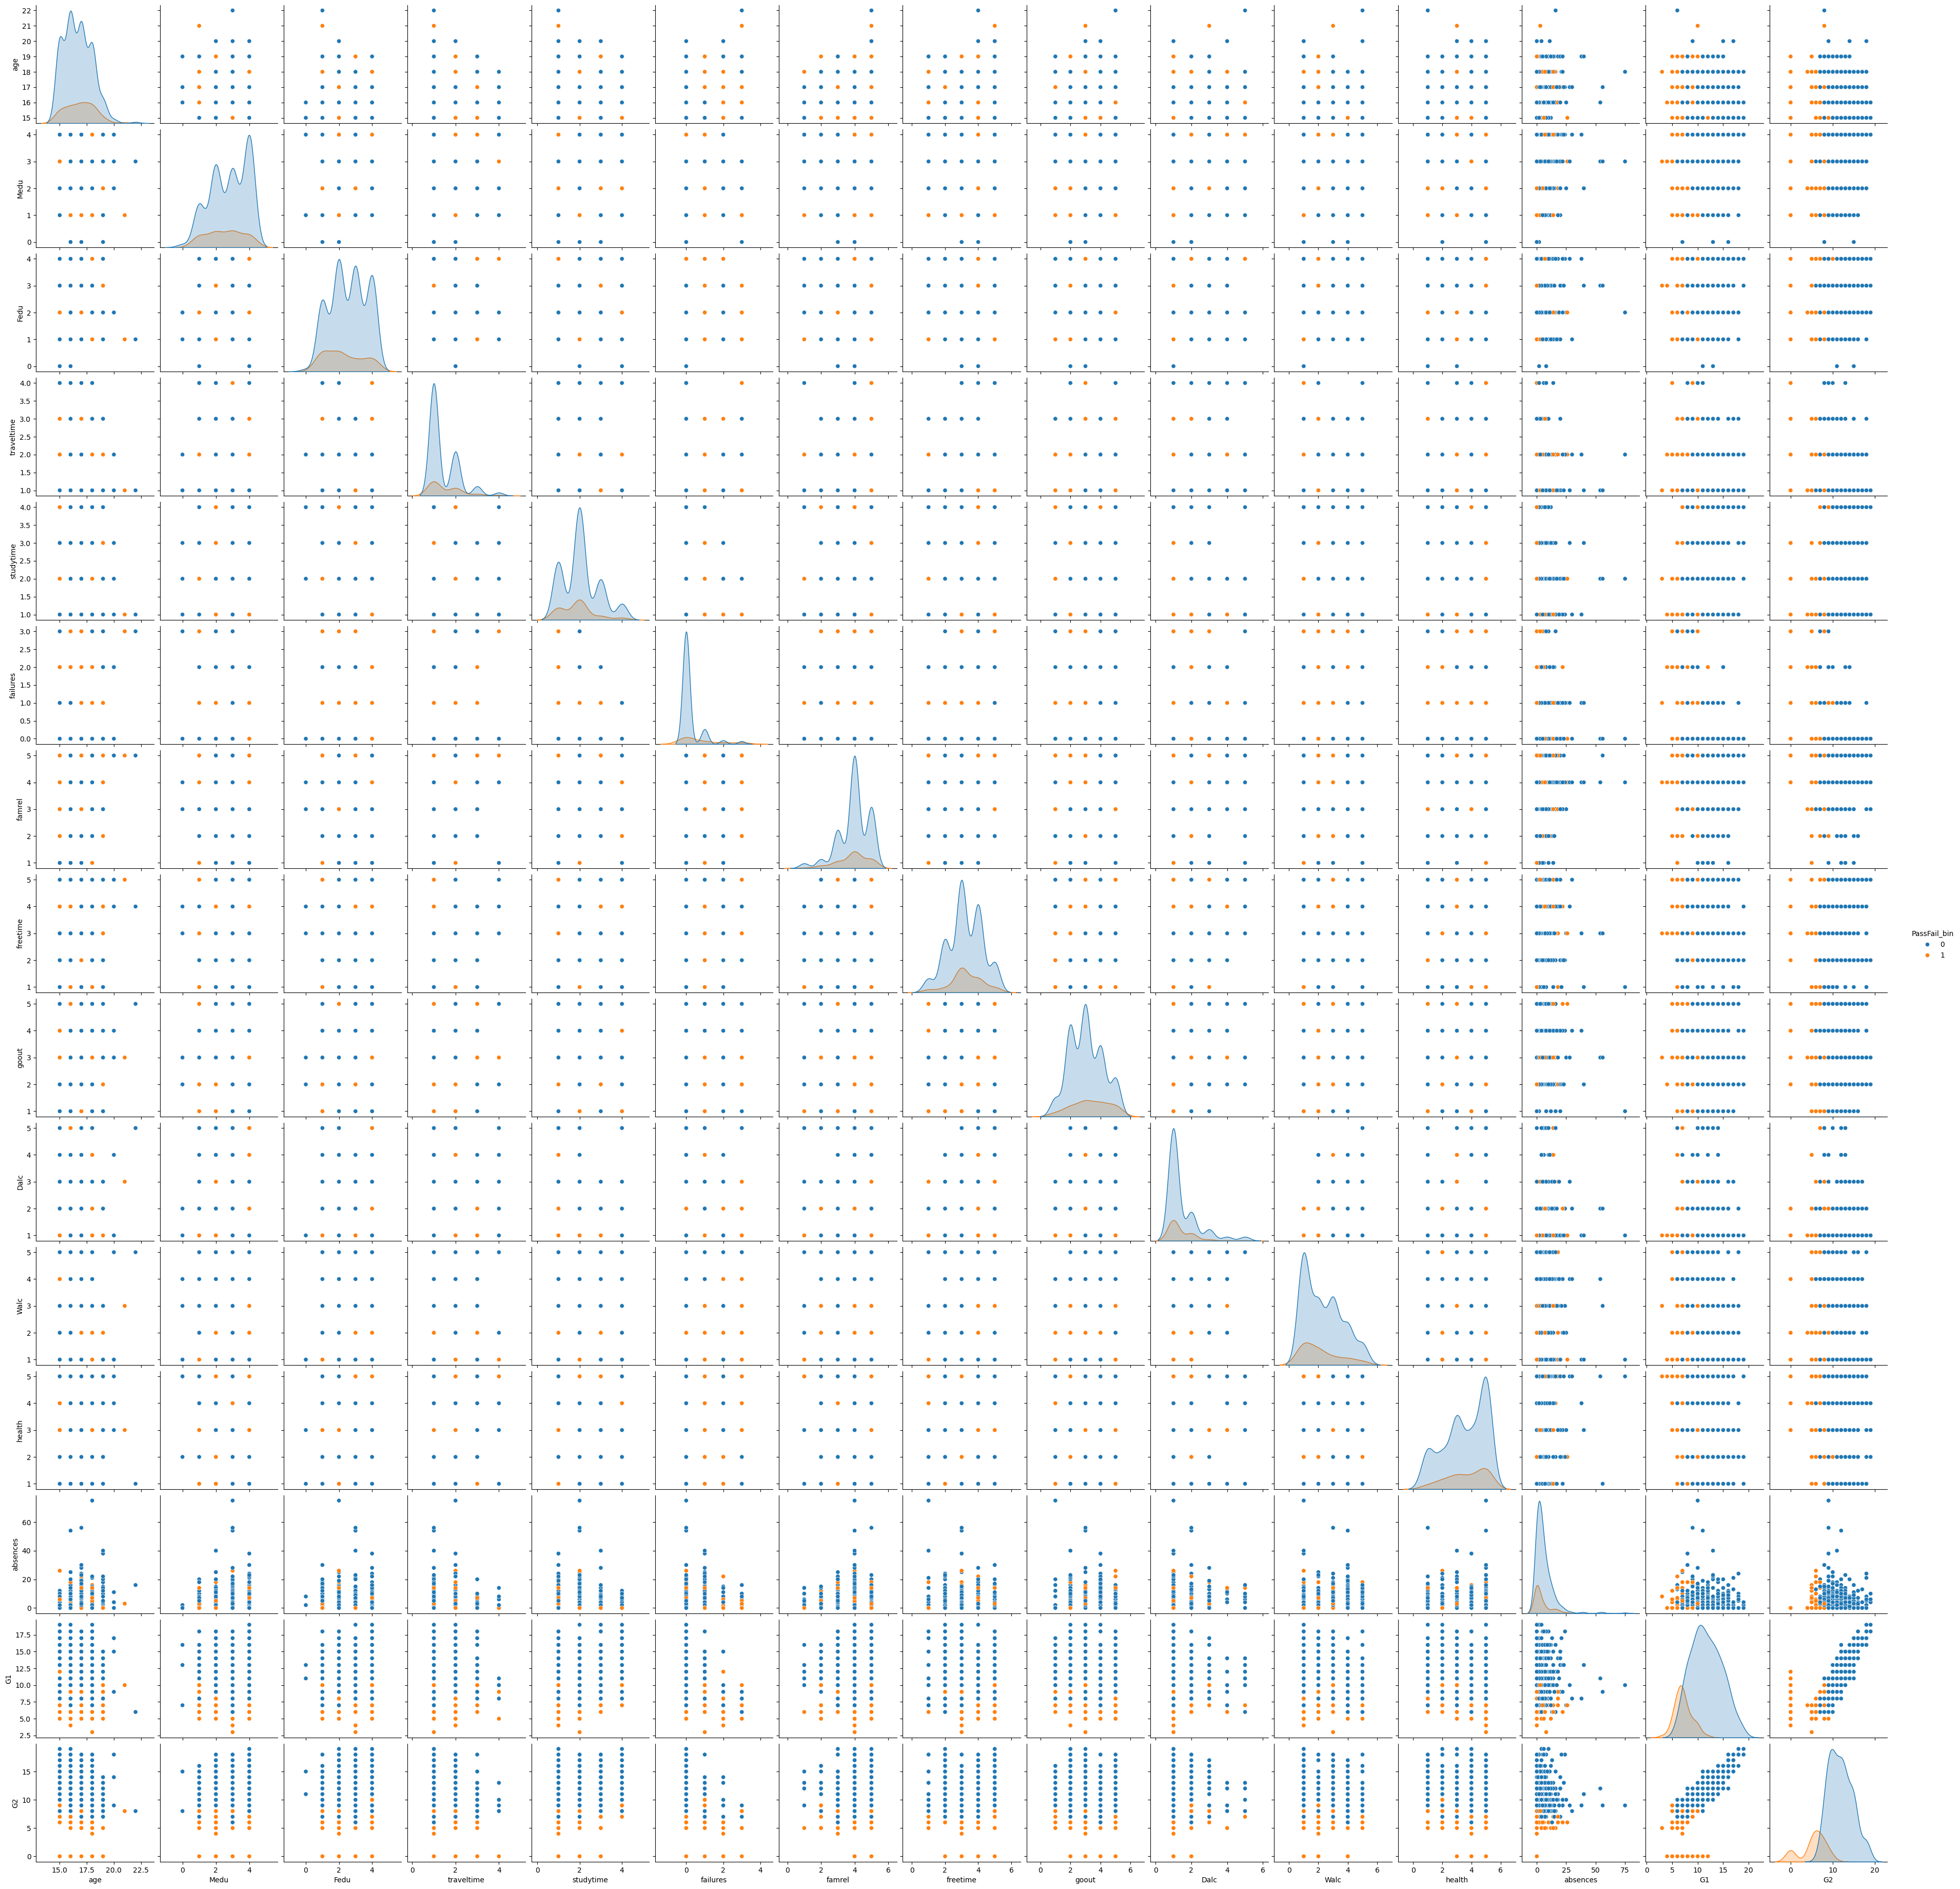

In [42]:
# Pair Plot
sb.pairplot(pkmdf[numeric_cols + ['PassFail_bin']], hue='PassFail_bin', diag_kind="kde")
plt.show()


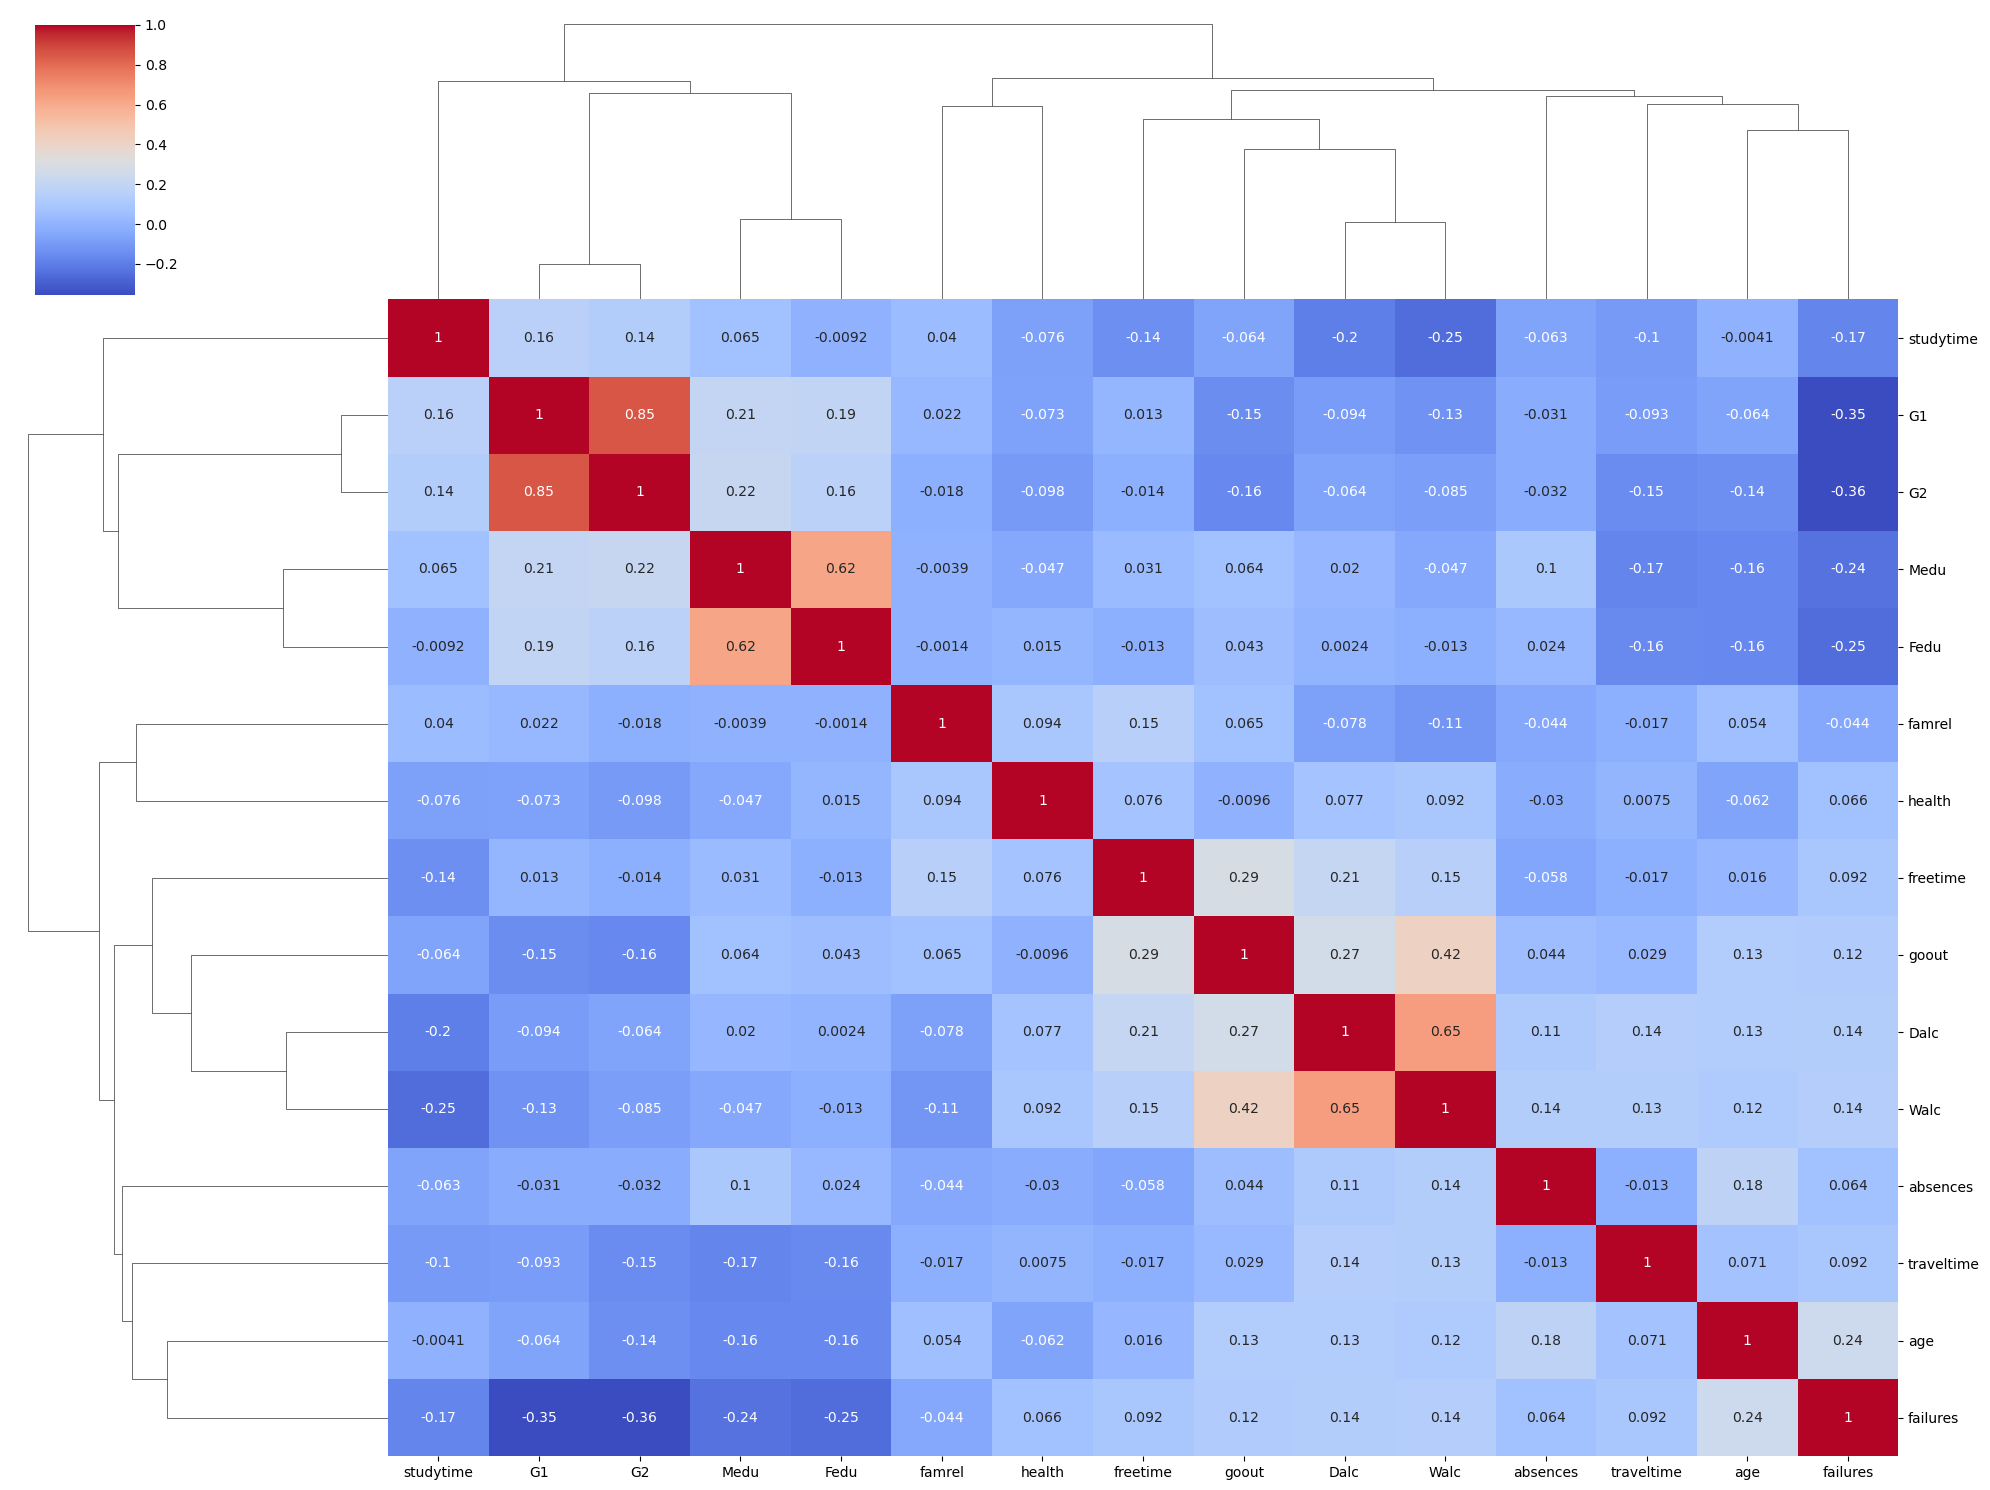

In [43]:
# Cluster Map
sb.clustermap(pkmdf[numeric_cols].corr(),
               cmap="coolwarm",
               figsize=(20,15),
               annot=True)  # annot=True adds correlation values
plt.show()

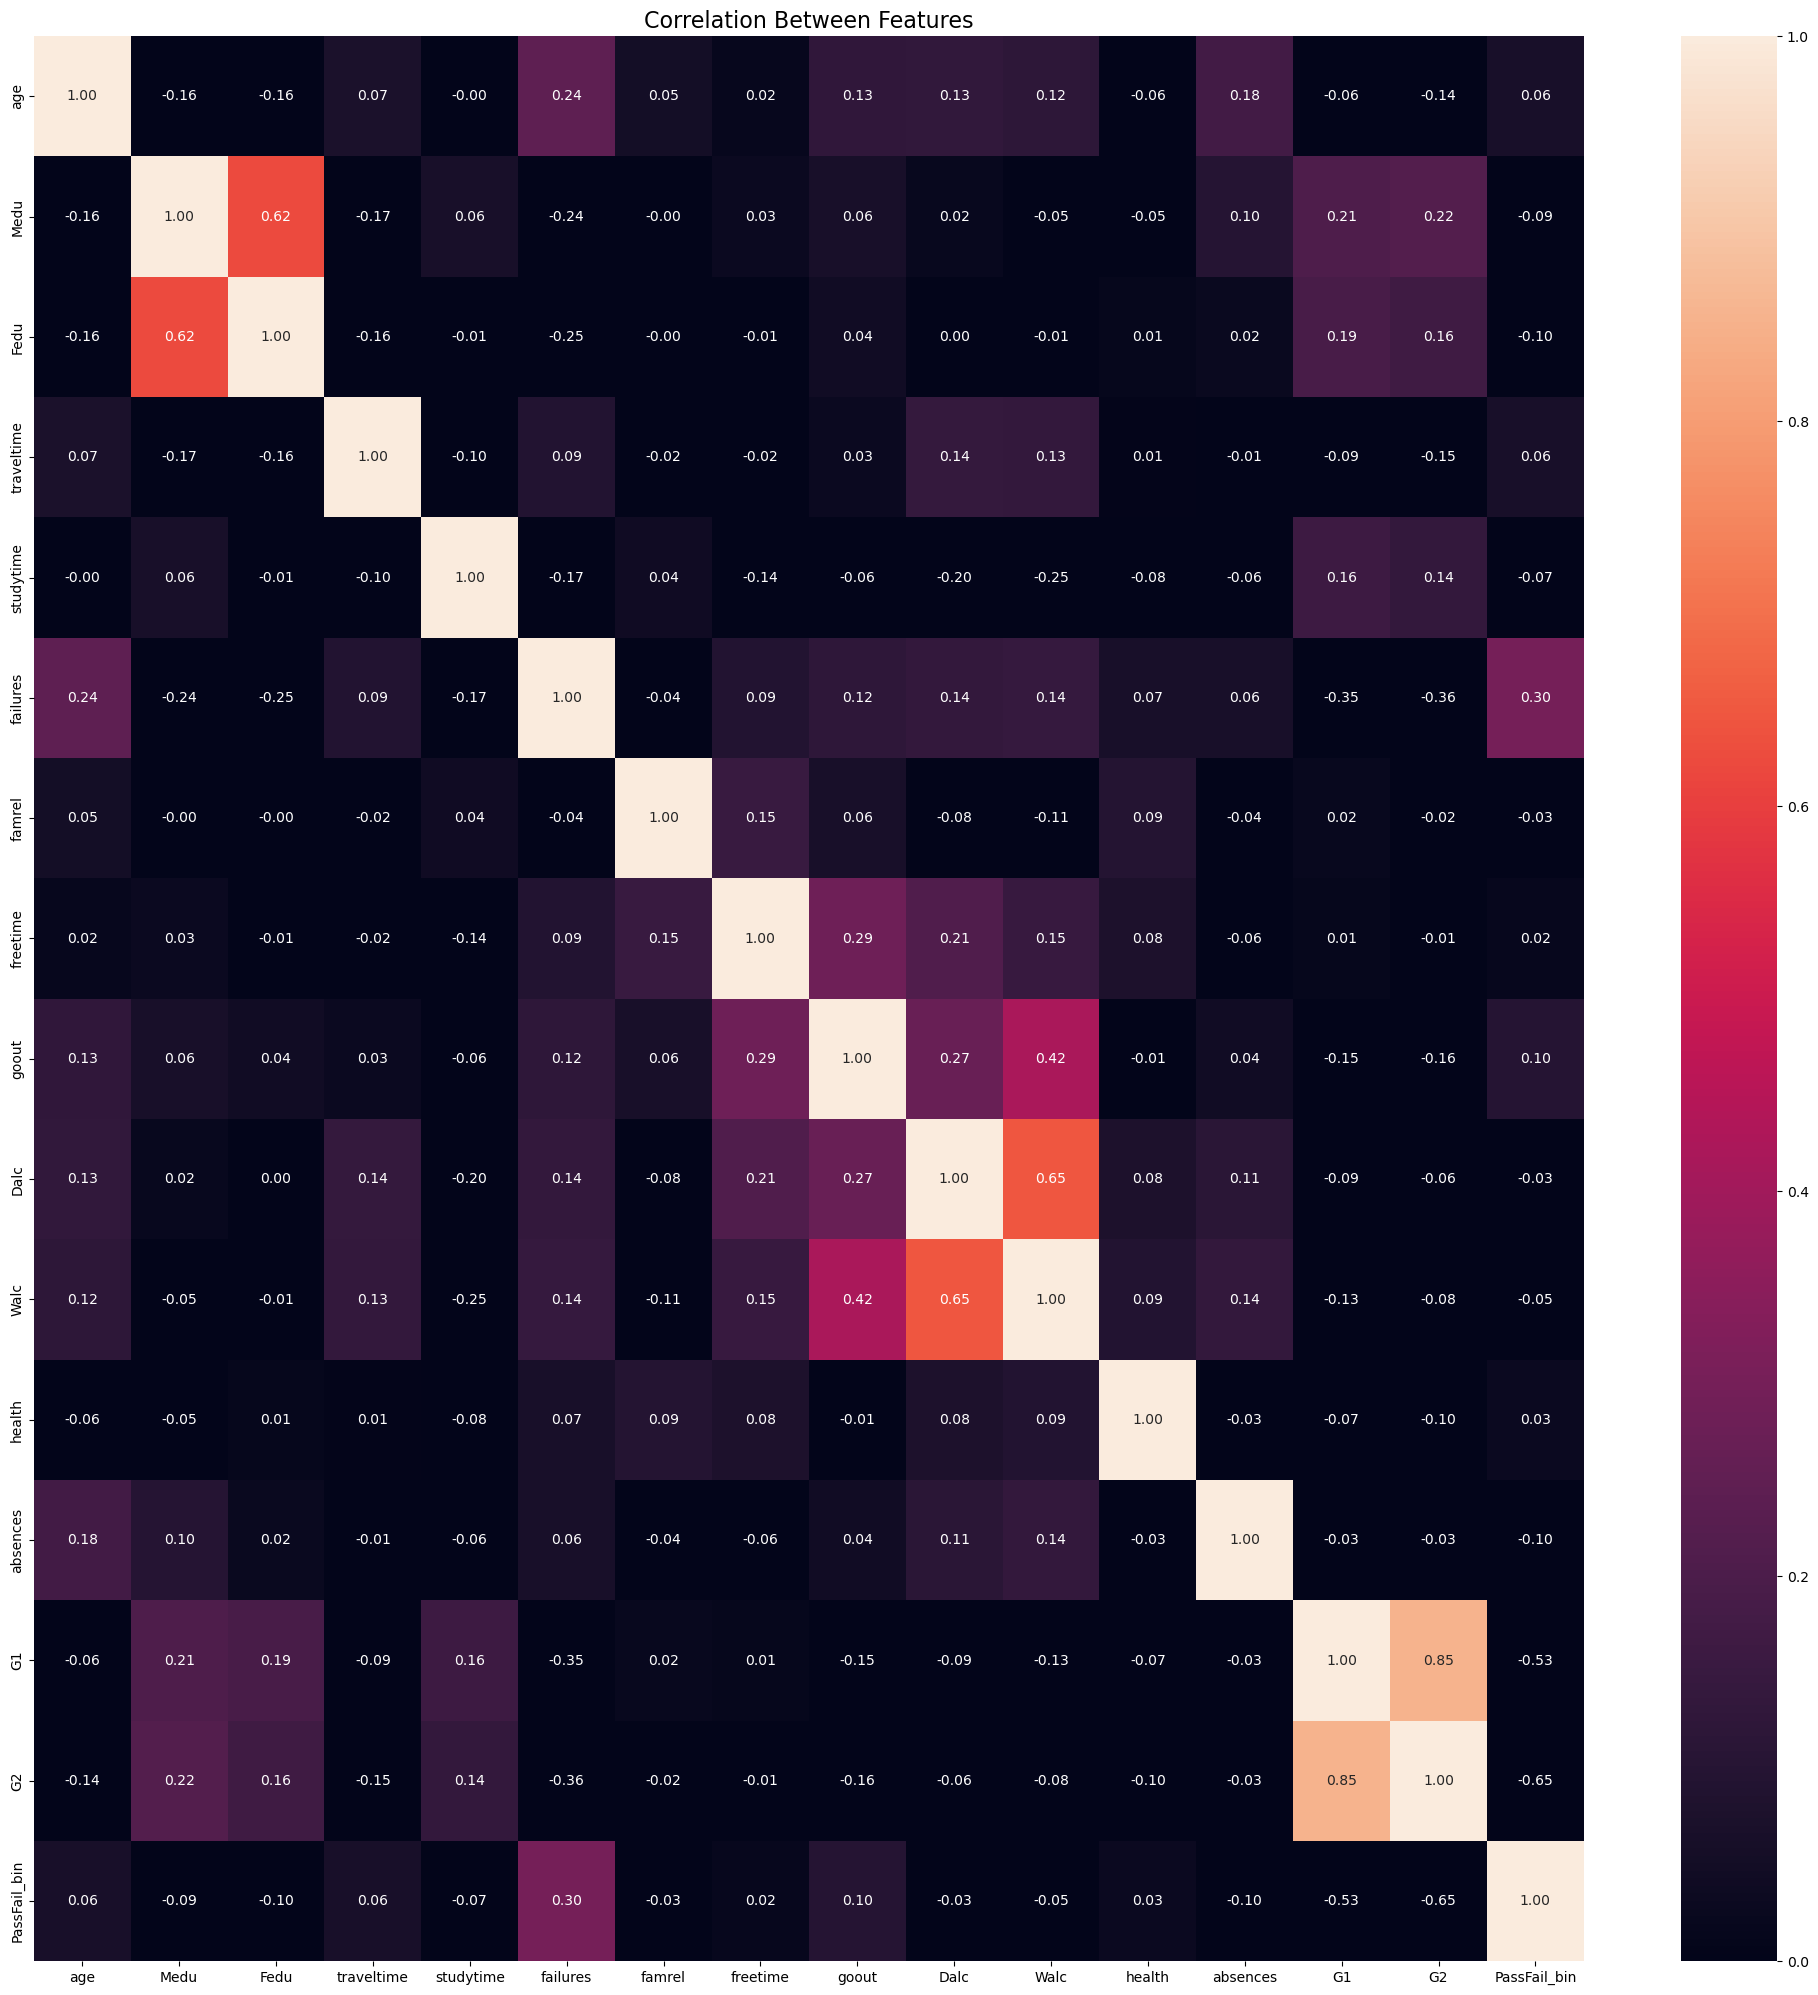

In [45]:
# Correlation between features
plt.figure(figsize=(25, 25))
sb.heatmap(pkmdf.select_dtypes(include=np.number).corr(), vmin = 0, vmax = 1, annot = True, fmt = ".2f")
plt.title("Correlation Between Features", fontsize=16)
plt.show()

# **Feature Transformation**

**Nominal Features --> One Hot Encoding**

In [52]:
pkmdf = pd.get_dummies(pkmdf, columns=nominal_cols, drop_first=True)
pkmdf.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid',
       'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'PassFail_bin', 'Mjob_health', 'Mjob_other', 'Mjob_services',
       'Mjob_teacher', 'Fjob_health', 'Fjob_other', 'Fjob_services',
       'Fjob_teacher', 'reason_home', 'reason_other', 'reason_reputation',
       'guardian_mother', 'guardian_other'],
      dtype='object')

**Boolean Features --> Maps to 1 and 0**


In [55]:
pkmdf['school'] = pkmdf['school'].map({'GP': 1, 'MS': 0})
pkmdf['sex'] = pkmdf['sex'].map({'M': 1, 'F': 0})
pkmdf['address'] = pkmdf['address'].map({'U': 1, 'R': 0})
pkmdf['famsize'] = pkmdf['famsize'].map({'LE3': 1, 'GT3': 0})
pkmdf['Pstatus'] = pkmdf['Pstatus'].map({'T': 1, 'A': 0})
pkmdf['schoolsup'] = pkmdf['schoolsup'].map({'yes': 1, 'no': 0})
pkmdf['paid'] = pkmdf['paid'].map({'yes': 1, 'no': 0})
pkmdf['activities'] = pkmdf['activities'].map({'yes': 1, 'no': 0})
pkmdf['nursery'] = pkmdf['nursery'].map({'yes': 1, 'no': 0})
pkmdf['higher'] = pkmdf['higher'].map({'yes': 1, 'no': 0})
pkmdf['internet'] = pkmdf['internet'].map({'yes': 1, 'no': 0})
pkmdf['romantic'] = pkmdf['romantic'].map({'yes': 1, 'no': 0})
pkmdf['famsup'] = pkmdf['famsup'].map({'yes': 1, 'no': 0})

In [57]:
pkmdf

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,...,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other
0,1,0,18,1,0,0,4,4,2,2,...,False,False,False,False,True,False,False,False,True,False
1,1,0,17,1,0,1,1,1,1,2,...,False,False,True,False,False,False,False,False,False,False
2,1,0,15,1,1,1,1,1,1,2,...,False,False,True,False,False,False,True,False,True,False
3,1,0,15,1,0,1,4,2,1,3,...,False,False,False,True,False,True,False,False,True,False
4,1,0,16,1,0,1,3,3,1,2,...,False,False,True,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,0,1,20,1,1,0,2,2,1,2,...,False,False,False,True,False,False,False,False,False,True
391,0,1,17,1,1,1,3,1,2,1,...,False,False,False,True,False,False,False,False,True,False
392,0,1,21,0,0,1,1,1,1,1,...,False,False,True,False,False,False,False,False,False,True
393,0,1,18,0,1,1,3,2,3,1,...,False,False,True,False,False,False,False,False,True,False


# **Feature Reduction**

Feature Reduction Main Consideration
- Correlation between features and target
- Correlation between features
- Variance of feature


In [60]:
# Correlation of all features with Target
corr_with_target = pkmdf.corr()['PassFail_bin'].sort_values(ascending=False)
print(corr_with_target)

PassFail_bin         1.000000
failures             0.300005
goout                0.097670
romantic             0.092872
Mjob_other           0.083204
age                  0.063810
traveltime           0.063127
Fjob_other           0.060553
famsup               0.042380
schoolsup            0.038792
health               0.029555
guardian_mother      0.023250
Fjob_teacher         0.021880
freetime             0.016741
guardian_other       0.007997
Pstatus              0.005778
school              -0.017529
activities          -0.021488
nursery             -0.027022
Dalc                -0.027358
famrel              -0.030363
reason_other        -0.031784
Mjob_services       -0.034024
reason_home         -0.034358
reason_reputation   -0.039134
Walc                -0.048347
Fjob_services       -0.054145
Mjob_teacher        -0.061412
Fjob_health         -0.069618
studytime           -0.074994
famsize             -0.076123
Medu                -0.093722
internet            -0.094259
sex       

In [62]:
# Drop features with low absolute correlation (< 0.05)
low_corr_features = corr_with_target[abs(corr_with_target) < 0.05].index.tolist()
pkmdf = pkmdf.drop(columns=low_corr_features)

print("Dropped features:", low_corr_features)
print("Remaining features:", pkmdf.columns.tolist())

Dropped features: ['famsup', 'schoolsup', 'health', 'guardian_mother', 'Fjob_teacher', 'freetime', 'guardian_other', 'Pstatus', 'school', 'activities', 'nursery', 'Dalc', 'famrel', 'reason_other', 'Mjob_services', 'reason_home', 'reason_reputation', 'Walc']
Remaining features: ['sex', 'age', 'address', 'famsize', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'paid', 'higher', 'internet', 'romantic', 'goout', 'absences', 'G1', 'G2', 'PassFail_bin', 'Mjob_health', 'Mjob_other', 'Mjob_teacher', 'Fjob_health', 'Fjob_other', 'Fjob_services']


In [64]:
# Remove 'G1' that highly correlated with 'G2'
pkmdf=pkmdf.drop(columns=['G1'])

In [66]:
# Variances
variances = pkmdf.var()
print(variances.sort_values())


Fjob_health       0.043603
higher            0.048191
Mjob_health       0.078867
Mjob_teacher      0.125593
internet          0.139523
PassFail_bin      0.146180
address           0.173591
Fjob_services     0.202557
famsize           0.205834
romantic          0.223068
Mjob_other        0.230123
Fjob_other        0.248191
paid              0.248885
sex               0.249926
traveltime        0.486513
failures          0.553017
studytime         0.704324
Fedu              1.184180
Medu              1.198445
goout             1.239388
age               1.628285
G2               14.148917
absences         64.049541
dtype: float64


In [68]:
# Variance
selector = VarianceThreshold(threshold=0.01)
X_reduced = selector.fit_transform(pkmdf)

kept_features = pkmdf.columns[selector.get_support()]
dropped_features = pkmdf.columns[~selector.get_support()]

print("Kept:", kept_features)
print("Dropped:", dropped_features)


Kept: Index(['sex', 'age', 'address', 'famsize', 'Medu', 'Fedu', 'traveltime',
       'studytime', 'failures', 'paid', 'higher', 'internet', 'romantic',
       'goout', 'absences', 'G2', 'PassFail_bin', 'Mjob_health', 'Mjob_other',
       'Mjob_teacher', 'Fjob_health', 'Fjob_other', 'Fjob_services'],
      dtype='object')
Dropped: Index([], dtype='object')


In [70]:
# Encoded Boolean and Nominal Features Class Balance and Variance
binary_cols = [col for col in pkmdf.columns if pkmdf[col].nunique() == 2]
for col in binary_cols:
    counts = pkmdf[col].value_counts(normalize=True)
    print(f"{col}: {counts.to_dict()} (variance={pkmdf[col].var():.4f})")


sex: {0: 0.5265822784810127, 1: 0.47341772151898737} (variance=0.2499)
address: {1: 0.7772151898734178, 0: 0.22278481012658227} (variance=0.1736)
famsize: {0: 0.7113924050632912, 1: 0.28860759493670884} (variance=0.2058)
paid: {0: 0.5417721518987342, 1: 0.4582278481012658} (variance=0.2489)
higher: {1: 0.9493670886075949, 0: 0.05063291139240506} (variance=0.0482)
internet: {1: 0.8329113924050633, 0: 0.1670886075949367} (variance=0.1395)
romantic: {0: 0.6658227848101266, 1: 0.3341772151898734} (variance=0.2231)
PassFail_bin: {0: 0.8227848101265823, 1: 0.17721518987341772} (variance=0.1462)
Mjob_health: {False: 0.9139240506329114, True: 0.08607594936708861} (variance=0.0789)
Mjob_other: {False: 0.6430379746835443, True: 0.3569620253164557} (variance=0.2301)
Mjob_teacher: {False: 0.8531645569620253, True: 0.1468354430379747} (variance=0.1256)
Fjob_health: {False: 0.9544303797468354, True: 0.04556962025316456} (variance=0.0436)
Fjob_other: {True: 0.549367088607595, False: 0.450632911392405

In [72]:
features = pkmdf.drop(columns=['PassFail_bin'])

In [74]:
features

,sex,age,address,famsize,Medu,Fedu,traveltime,studytime,failures,paid,...,romantic,goout,absences,G2,Mjob_health,Mjob_other,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services
0,0,18,1,0,4,4,2,2,0,0,...,0,4,6,6,False,False,False,False,False,False
1,0,17,1,0,1,1,1,2,0,0,...,0,3,4,5,False,False,False,False,True,False
2,0,15,1,1,1,1,1,2,3,1,...,0,2,10,8,False,False,False,False,True,False
3,0,15,1,0,4,2,1,3,0,1,...,1,2,2,14,True,False,False,False,False,True
4,0,16,1,0,3,3,1,2,0,1,...,0,2,4,10,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,1,20,1,1,2,2,1,2,2,1,...,0,4,11,9,False,False,False,False,False,True
391,1,17,1,1,3,1,2,1,0,0,...,0,5,3,16,False,False,False,False,False,True
392,1,21,0,0,1,1,1,1,3,0,...,0,3,3,8,False,True,False,False,True,False
393,1,18,0,1,3,2,3,1,0,0,...,0,1,0,12,False,False,False,False,True,False


**Standardization of Numeric Features**

In [77]:
numeric_cols = [col for col in numeric_cols if col not in ['G1','famsup','schoolsup','health','guardian_mother','Fjob_teacher','freetime','guardian_other','Pstatus','school','activities', 'nursery','Dalc','famrel','reason_other','Mjob_services','reason_home','reason_reputation',"Walc"]]
numeric_cols

['age',
 'Medu',
 'Fedu',
 'traveltime',
 'studytime',
 'failures',
 'goout',
 'absences',
 'G2']

In [79]:
scaler = StandardScaler()
pkmdf[numeric_cols] = scaler.fit_transform(pkmdf[numeric_cols])


**Split Data Using Stratified Sampling**

In [82]:
X_train, X_test, y_train, y_test = train_test_split(features, label, test_size=0.2, stratify=label, random_state=42)


## **Build Random Forest**

In [ ]:
# Create Baseline Model
rf = RandomForestClassifier(random_state=42)

In [ ]:
# Define Grid for Hyperparameter Tuning
param_dist = {
    'n_estimators': [50, 100, 200, 500],
    'max_depth': [None, 10, 20, 30, 40],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'class_weight': [None, 'balanced']
}

##### Hyperparameter Tuning Using Random Search

In [ ]:
# Tune Hyperparameter Using Random Search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=50,              # number of random combinations to try
    cv=5,                   # 5-fold cross-validation
    scoring='f1',           # use F1-score for imbalanced data
    random_state=42,
    n_jobs=-1               # use all CPU cores
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'class_weight': [None, 'balanced'],
                                        'max_depth': [None, 10, 20, 30, 40],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [50, 100, 200, 500]},
                   random_state=42, scoring='f1')

In [ ]:
print("Random Forest Best Parameters:", random_search.best_params_)
print("Fandom Forest Best Score:", random_search.best_score_)

Random Forest Best Parameters: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 30, 'class_weight': None}
Fandom Forest Best Score: 0.8412814645308924


##### Train and predict using both models

In [ ]:
# Train rf model using best paramaters
start_rf_bp = time.time()
rf_bp = RandomForestClassifier(**random_search.best_params_, random_state=42)
rf_bp.fit(X_train, y_train)
end_rf_bp = time.time()

train_time_rf_bp = end_rf_bp - start_rf_bp
print("Train Time for Tuned Random Forest:", train_time_rf_bp)

y_pred_rf_bp_ = rf_bp.predict(X_test)

Train Time for Tuned Random Forest: 0.5997066497802734


In [ ]:
# Train baseline rf model
start_rf = time.time()
rf = RandomForestClassifier(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
end_rf = time.time()

train_time_rf = end_rf - start_rf
print("Train Time for Baseline Random Forest:", train_time_rf)

y_pred_rf = rf.predict(X_test)

Train Time for Baseline Random Forest: 0.061274051666259766


In [ ]:
# Best-parameters model scores
acc_bp = accuracy_score(y_test, y_pred_rf_bp_)
prec_bp = precision_score(y_test, y_pred_rf_bp_)
recall_bp = recall_score(y_test, y_pred_rf_bp_)
f1_bp = f1_score(y_test, y_pred_rf_bp_)

# Baseline model scores
acc_base = accuracy_score(y_test, y_pred_rf)
prec_base = precision_score(y_test, y_pred_rf)
recall_base = recall_score(y_test, y_pred_rf)
f1_base = f1_score(y_test, y_pred_rf)

comparison_df = pd.DataFrame({
    "Model": ["Baseline RF", "Best Params RF"],
    "Accuracy": [acc_base, acc_bp],
    "Precision": [prec_base, prec_bp],
    "Recall": [recall_base, recall_bp],
    "F1-Score": [f1_base, f1_bp]
})

print(comparison_df)

            Model  Accuracy  Precision    Recall  F1-Score
0     Baseline RF  0.936709   0.846154  0.785714  0.814815
1  Best Params RF  0.911392   0.769231  0.714286  0.740741


##### Evaluate Best Random Forest Model

In [ ]:
#Evaluation 1: Train-Test Accuracy
train_pred_rf = rf.predict(X_train)
train_acc_rf = accuracy_score(y_train, train_pred_rf)
test_acc_rf = accuracy_score(y_test, y_pred_rf)

print("Train Accuracy:", train_acc_rf)
print("Test Accuracy:",test_acc_rf)

# To check model overfitting or underfitting

Train Accuracy: 1.0
Test Accuracy: 0.9367088607594937


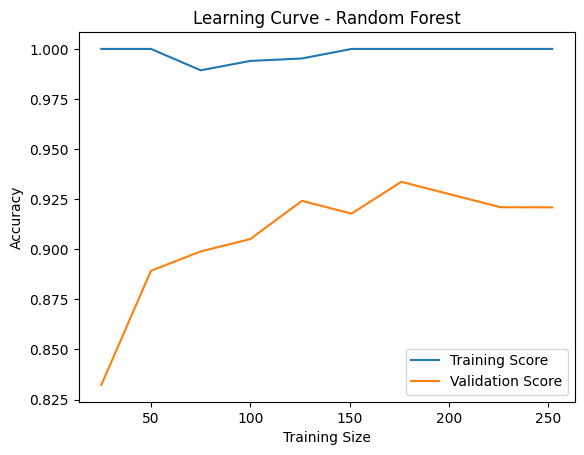

In [ ]:
#Evaluation 2: Learning curve
train_sizes, train_scores, val_scores = learning_curve(
    RandomForestClassifier(n_estimators=50, random_state=42),
    X_train, y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, val_mean, label='Validation Score')
plt.legend()
plt.xlabel('Training Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Random Forest')
plt.show()

AUC Score: 0.9357142857142857


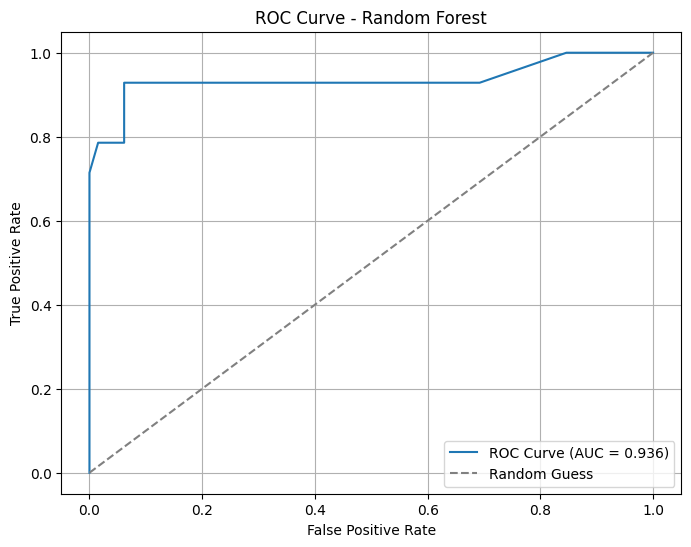

In [ ]:
#Evaluation 3: ROC curve
# Get prediction value
y_prob = rf.predict_proba(X_test)[:, 1]
# Compute ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
print("AUC Score:", auc_score)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(True)

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96        65
           1       0.85      0.79      0.81        14

    accuracy                           0.94        79
   macro avg       0.90      0.88      0.89        79
weighted avg       0.94      0.94      0.94        79



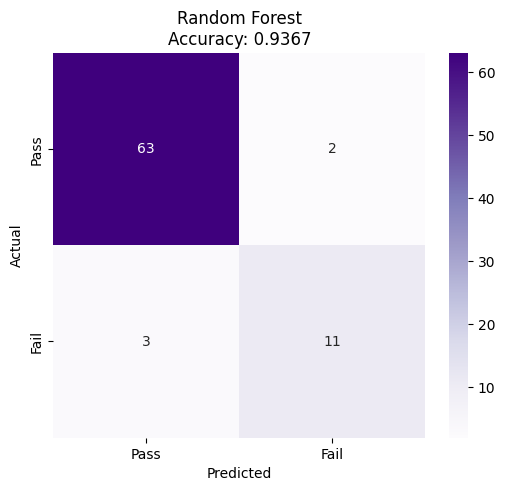

In [ ]:
#Evaluation 4: Confusion Matrix
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 5))
sb.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples',
           xticklabels=['Pass', 'Fail'], yticklabels=['Pass', 'Fail'])
plt.title(f"Random Forest\nAccuracy: {acc_base:.4f}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

## **Bulid XGBoost**

In [172]:
# Create Baseline Model
xgb = XGBClassifier(random_state=42, eval_metric="logloss",)

In [174]:
# Define Parameter for Hyperparameter Tuning
param_dist = {
    'n_estimators': [100, 200, 500],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'scale_pos_weight': [1, 5, 10],
    'reg_alpha': [0, 0.1, 0.5, 1, 5],
    'reg_lambda': [0, 0.5, 1, 2, 5],
    'gamma': [0, 0.5, 1, 2]
}

##### Hyperparameter Tuning Using Random Search

In [177]:
# Tune Hyperparameter Using Random Search
random_search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

In [179]:
random_search_xgb.fit(X_train, y_train)

,estimator,"XGBClassifier...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.6, 0.8, ...], 'gamma': [0, 0.5, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], ...}"
,n_iter,50
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [181]:
print("XGBoost Best Parameters:", random_search_xgb.best_params_)
print("XGBoost Forest Best CV Score:", random_search_xgb.best_score_)

XGBoost Best Parameters: {'subsample': 0.8, 'scale_pos_weight': 1, 'reg_lambda': 0.5, 'reg_alpha': 5, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.6}
XGBoost Forest Best CV Score: 0.8227100359594639


In [183]:
# Train baseline xgboost model
start_xgb = time.time()
xgb = XGBClassifier(random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)
end_xgb = time.time()

train_time_xgb = end_xgb - start_xgb
print("Train Time for Baseline XGBoost:", train_time_xgb)

y_pred_xg = xgb.predict(X_test)

Train Time for Baseline XGBoost: 0.036986589431762695


In [185]:
# Train tuned xgboost
start_xgb_bp = time.time()
xgb_bp = XGBClassifier(**random_search_xgb.best_params_, random_state=42, eval_metric="logloss")
xgb_bp.fit(X_train, y_train)
end_xgb_bp = time.time()

train_time_xgb_bp = end_xgb_bp - start_xgb_bp
print("Train Time for Tuned XGBoost:", train_time_xgb_bp)

y_pred_xg_bp_ = xgb_bp.predict(X_test)


Train Time for Tuned XGBoost: 0.033331871032714844


In [187]:
# Best-parameters model scores
acc_bp_xgb = accuracy_score(y_test, y_pred_xg_bp_)
prec_bp_xgb = precision_score(y_test, y_pred_xg_bp_)
recall_bp_xgb = recall_score(y_test, y_pred_xg_bp_)
f1_bp_xgb = f1_score(y_test, y_pred_xg_bp_)

# Baseline model scores
acc_base_xgb = accuracy_score(y_test, y_pred_xg)
prec_base_xgb = precision_score(y_test, y_pred_xg)
recall_base_xgb = recall_score(y_test, y_pred_xg)
f1_base_xgb = f1_score(y_test, y_pred_xg)

comparison_df = pd.DataFrame({
    "Model": ["Baseline XGB", "Best Params XGB"],
    "Accuracy": [acc_base_xgb, acc_bp_xgb],
    "Precision": [prec_base_xgb, prec_bp_xgb],
    "Recall": [recall_base_xgb, recall_bp_xgb],
    "F1-Score": [f1_base_xgb, f1_bp_xgb]
})

print(comparison_df)

             Model  Accuracy  Precision    Recall  F1-Score
0     Baseline XGB  0.924051   0.750000  0.857143  0.800000
1  Best Params XGB  0.911392   0.769231  0.714286  0.740741


##### Evaluate Best XGBoost Model

In [198]:
#Evaluation 1: Train-Test Accuracy
train_pred_xg = xgb.predict(X_train)
train_acc_xg = accuracy_score(y_train, train_pred_xg)
test_acc_xg = accuracy_score(y_test, y_pred_xg)

print("Train Accuracy:", train_acc_xg)
print("Test Accuracy:",test_acc_xg)

Train Accuracy: 1.0
Test Accuracy: 0.9240506329113924


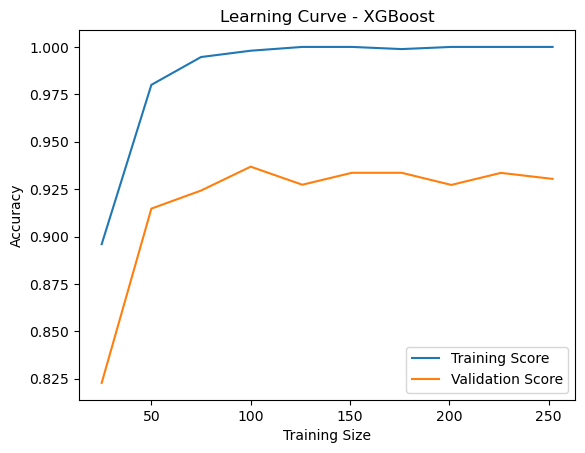

In [164]:
#Evaluation 2: Learning curve
train_sizes, train_scores, val_scores = learning_curve(
    xgb,
    X_train, y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, val_mean, label='Validation Score')
plt.legend()
plt.xlabel('Training Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve - XGBoost')
plt.show()

AUC Score: 0.9824175824175825


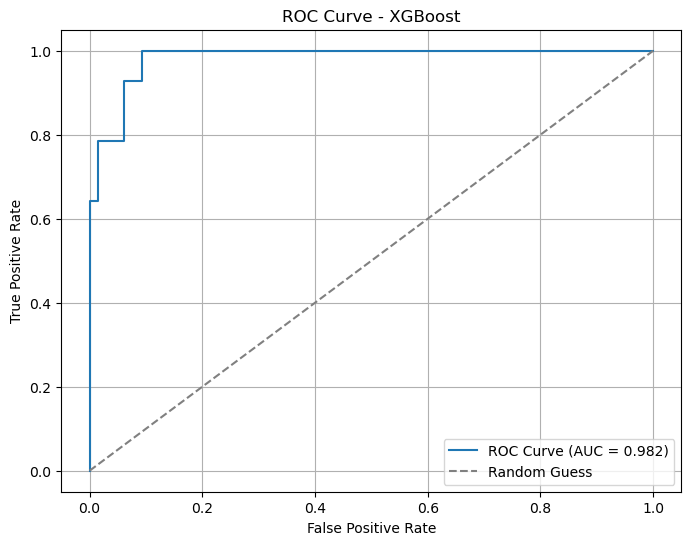

In [200]:
#Evaluation 3: ROC curve
y_prob = xgb.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
print("AUC Score:", auc_score)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.grid(True)

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.95        65
           1       0.75      0.86      0.80        14

    accuracy                           0.92        79
   macro avg       0.86      0.90      0.88        79
weighted avg       0.93      0.92      0.93        79



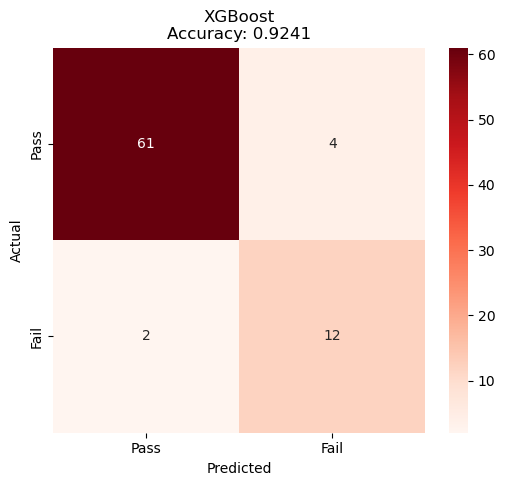

In [168]:
#Evaluation 4: Confusion Matrix
print("XGBoost Classification Report:")
print(classification_report(y_test, y_pred_xg))

cm_xg = confusion_matrix(y_test, y_pred_xg)
plt.figure(figsize=(6, 5))
sb.heatmap(cm_xg, annot=True, fmt='d', cmap='Reds',
           xticklabels=['Pass', 'Fail'], yticklabels=['Pass', 'Fail'])
plt.title(f"XGBoost\nAccuracy: {acc_base_xgb:.4f}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

## **Build SVM**

In [ ]:
# Create baseline SVM
baseline_svm = SVC(random_state=42)

In [ ]:
# Define parameter for SVM hyperparameter tuning
param_grid = {
    'C': [5, 10, 50, 100, 500],
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'gamma': [0.0001, 0.001, 0.01, 0.1, 1, 'scale', 'auto']
}

##### Hyperparameter Tuning Using Grid Search


In [ ]:
# Create GridSearchCV object
grid_search = GridSearchCV(
    SVC(random_state=42),
    param_grid,
    cv=5,  # 5-fold cross-validation
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)
# Fit GridSearchCV
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 140 candidates, totalling 700 fits


GridSearchCV(cv=5, estimator=SVC(random_state=42), n_jobs=-1,
             param_grid={'C': [5, 10, 50, 100, 500],
                         'gamma': [0.0001, 0.001, 0.01, 0.1, 1, 'scale',
                                   'auto'],
                         'kernel': ['linear', 'rbf', 'poly', 'sigmoid']},
             scoring='accuracy', verbose=2)

In [ ]:
print("SVM Best Parameters:", grid_search.best_params_)
print("SVM Best Score:", grid_search.best_score_)

SVM Best Parameters: {'C': 100, 'gamma': 0.0001, 'kernel': 'rbf'}
SVM Best Score: 0.946279761904762


##### Test Different Kernals

In [ ]:
# Kernal Comparisons
kernels = ['linear', 'rbf', 'poly', 'sigmoid']
results = []

for k in kernels:
    print(f"\n========== {k.upper()} KERNEL ==========")

    model = SVC(kernel=k, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')

    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")

    results.append([k, acc, f1])

results_df = pd.DataFrame(results, columns=['Kernel', 'Accuracy', 'F1 Score'])
print("\n--- Kernel Comparison ---")
print(results_df)

# Find index of best accuracy
best_idx = results_df['Accuracy'].idxmax()

# Get the best row
best_kernel = results_df.loc[best_idx]

print("\nBest Kernal:")
print(f"Name: {best_kernel['Kernel']}")
print(f"Accuracy: {best_kernel['Accuracy']:.4f}")
print(f"F1 Score: {best_kernel['F1 Score']:.4f}")


========== LINEAR KERNEL ==========
Accuracy: 0.9114
F1 Score: 0.9071

========== RBF KERNEL ==========
Accuracy: 0.9114
F1 Score: 0.8989

========== POLY KERNEL ==========
Accuracy: 0.9367
F1 Score: 0.9336

========== SIGMOID KERNEL ==========
Accuracy: 0.8734
F1 Score: 0.8428

--- Kernel Comparison ---
    Kernel  Accuracy  F1 Score
0   linear  0.911392  0.907075
1      rbf  0.911392  0.898888
2     poly  0.936709  0.933625
3  sigmoid  0.873418  0.842777

Best Kernal:
Name: poly
Accuracy: 0.9367
F1 Score: 0.9336


In [ ]:
# Find Best Tuned Poly Kernal
poly_grid = {
    'C': [0.1, 1, 10, 100],
    'degree': [2, 3, 4, 5],
    'gamma': ['scale', 'auto']
}

best_kernal_name = best_kernel['Kernel']

poly_search = GridSearchCV(
    SVC(kernel=best_kernal_name, random_state=42),
    poly_grid,
    cv=5,
    n_jobs=-1,
    verbose=2,
    scoring='f1'
)

poly_search.fit(X_train, y_train)

print("Best Poly Parameters:", poly_search.best_params_)
print("Best Poly CV Score:", poly_search.best_score_)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Poly Parameters: {'C': 10, 'degree': 2, 'gamma': 'scale'}
Best Poly CV Score: 0.8195989974937342


##### Train and Predict with All SVM Model

In [ ]:
# Train baseline SVM
start_svm = time.time()
svm = SVC(random_state=42)
svm.fit(X_train, y_train)
end_svm = time.time()

train_time_svm = end_svm - start_svm
print("Train Time for Baseline SVM:", train_time_svm)

y_pred_svm = svm.predict(X_test)

Train Time for Baseline SVM: 0.004548549652099609


In [ ]:
# Train SVM model using best parameter
start_svm_bp = time.time()
svm_bp = SVC(**grid_search.best_params_, random_state=42)
svm_bp.fit(X_train, y_train)
end_svm_bp = time.time()

train_time_svm_bp = end_svm_bp - start_svm_bp
print("Train Time for Tuned SVM:", train_time_svm_bp)

y_pred_svm_bp = svm_bp.predict(X_test)

Train Time for Tuned SVM: 0.005734920501708984


In [ ]:
# Train Untuned Best Kernal
start_untuned_poly = time.time()
svm_untuned_poly = SVC(kernel='poly', random_state=42)
svm_untuned_poly.fit(X_train, y_train)
end_untuned_poly = time.time()

train_time_untuned = end_untuned_poly - start_untuned_poly
print("Train Time for Untuned Poly Kernal:", train_time_untuned)

y_pred_untuned_poly = svm_untuned_poly.predict(X_test)

Train Time for Untuned Poly Kernal: 0.006866931915283203


In [ ]:
# Train Tuned Best Kernal
start_poly = time.time()
svm_poly = SVC(kernel='poly', **poly_search.best_params_, random_state=42)
svm_poly.fit(X_train, y_train)
end_poly = time.time()

train_time_poly = end_poly - start_poly
print("Train Time for Tuned Poly Kernal:", train_time_poly)

y_pred_poly = svm_poly.predict(X_test)

Train Time for Tuned Poly Kernal: 0.0063436031341552734


In [ ]:
# Baseline model scores
acc_base_svm = accuracy_score(y_test, y_pred_svm)
prec_base_svm = precision_score(y_test, y_pred_svm)
recall_base_svm = recall_score(y_test, y_pred_svm)
f1_base_svm = f1_score(y_test, y_pred_svm)

# Best-parameters model scores
acc_bp_svm = accuracy_score(y_test, y_pred_svm_bp)
prec_bp_svm = precision_score(y_test, y_pred_svm_bp)
recall_bp_svm = recall_score(y_test, y_pred_svm_bp)
f1_bp_svm = f1_score(y_test, y_pred_svm_bp)

# Untuned kernal model scores
acc_untuned_poly = accuracy_score(y_test, y_pred_untuned_poly)
prec_untuned_poly = precision_score(y_test, y_pred_untuned_poly)
recall_untuned_poly = recall_score(y_test, y_pred_untuned_poly)
f1_untuned_poly = f1_score(y_test, y_pred_untuned_poly)

# Tuned kernal model scores
acc_poly = accuracy_score(y_test, y_pred_poly)
prec_poly = precision_score(y_test, y_pred_poly)
recall_poly = recall_score(y_test, y_pred_poly)
f1_poly = f1_score(y_test, y_pred_poly)

comparison_df = pd.DataFrame({
    "Model": ["Baseline SVM", "Best Params SVM", "Untuned Kernal", "Tuned Kernal"],
    "Accuracy": [acc_base_svm, acc_bp_svm, acc_untuned_poly, acc_poly],
    "Precision": [prec_base_svm, prec_bp_svm, prec_untuned_poly, prec_poly],
    "Recall": [recall_base_svm, recall_bp_svm, recall_untuned_poly, recall_poly],
    "F1-Score": [f1_base_svm, f1_bp_svm, f1_untuned_poly, f1_poly]
})

print(comparison_df)

             Model  Accuracy  Precision    Recall  F1-Score
0     Baseline SVM  0.911392   1.000000  0.500000  0.666667
1  Best Params SVM  0.911392   0.818182  0.642857  0.720000
2   Untuned Kernal  0.936709   0.909091  0.714286  0.800000
3     Tuned Kernal  0.911392   0.818182  0.642857  0.720000


##### Evaluate Best SVM Model

In [ ]:
# Evaluation 1: Train-Test Accuracy
train_pred_svm = svm_untuned_poly.predict(X_train)
train_acc_svm = accuracy_score(y_train, train_pred_svm)
test_acc_svm = accuracy_score(y_test, y_pred_untuned_poly)

print("Train Accuracy:", train_acc_svm)
print("Test Accuracy:", test_acc_svm)

Train Accuracy: 0.9367088607594937
Test Accuracy: 0.9367088607594937


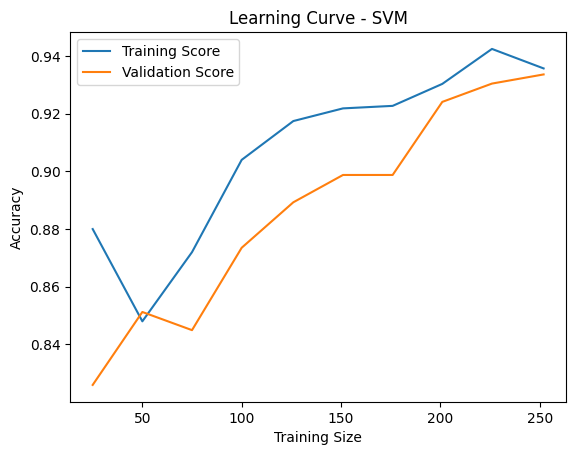

In [ ]:
# Evaluation 2: Learning Curve
train_sizes_svm, train_scores_svm, val_scores_svm = learning_curve(
    svm_untuned_poly,
    X_train, y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean_svm = train_scores_svm.mean(axis=1)
val_mean_svm = val_scores_svm.mean(axis=1)

plt.plot(train_sizes, train_mean_svm, label='Training Score')
plt.plot(train_sizes, val_mean_svm, label='Validation Score')
plt.legend()
plt.xlabel('Training Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve - SVM')
plt.show()

AUC Score: 0.9714285714285714


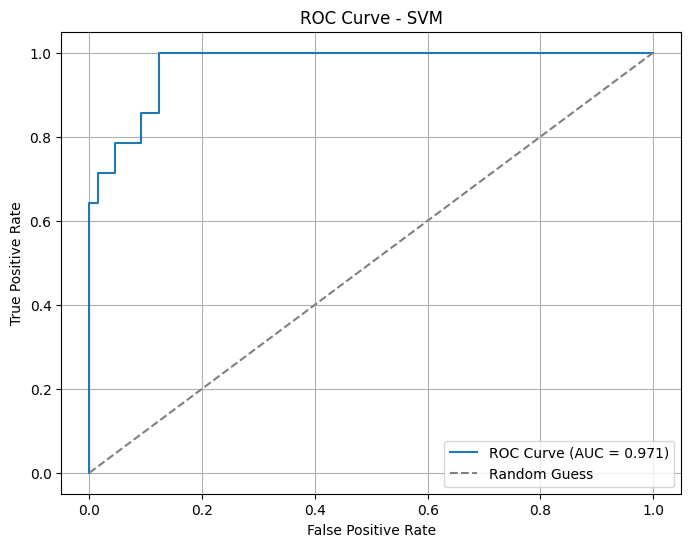

In [ ]:
# Evaluation 3: ROC Curve
y_prob_svm = svm_untuned_poly.decision_function(X_test)
fpr_svm, tpr_svm, thresholds_svm = roc_curve(y_test, y_prob_svm)
auc_score_svm = roc_auc_score(y_test, y_prob_svm)
print("AUC Score:", auc_score_svm)
plt.figure(figsize=(8,6))
plt.plot(fpr_svm, tpr_svm, label=f'ROC Curve (AUC = {auc_score_svm:.3f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend()
plt.grid(True)
plt.show()


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96        65
           1       0.91      0.71      0.80        14

    accuracy                           0.94        79
   macro avg       0.93      0.85      0.88        79
weighted avg       0.94      0.94      0.93        79



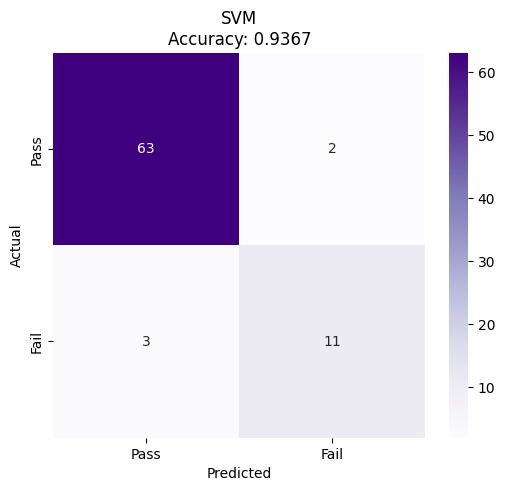

In [ ]:
# Evaluation 4: Confusion Matrix
print("\nSVM Classification Report:")
print(classification_report(
    y_test,
    y_pred_untuned_poly,
    target_names=['0', '1']
))
cm_svm = confusion_matrix(y_test, y_pred_untuned_poly)
plt.figure(figsize=(6, 5))
sb.heatmap(cm_rf, annot=True, fmt='d', cmap='Purples',
           xticklabels=['Pass', 'Fail'], yticklabels=['Pass', 'Fail'])
plt.title(f"SVM\nAccuracy: {acc_untuned_poly:.4f}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

## **Build Neural Network**

In [ ]:
# Build baseline model
baseline_nn = MLPClassifier(max_iter=1000, random_state=42)

In [ ]:
# Define parameter for NN hyperparameter tuning
param_grid_nn = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
    'activation': ['tanh', 'relu'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate': ['constant', 'adaptive'],
    'early_stopping': [True, False],
    'validation_fraction': [0.1, 0.2],
    'n_iter_no_change': [10, 20]
}

##### Hyperparameter Tuning Using Grid Search

In [ ]:
# Tune hyperparameters using GridSearchCV
grid_search_nn = GridSearchCV(
    MLPClassifier(max_iter=1000, random_state=42),
    param_grid_nn,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid_search_nn.fit(X_train, y_train)

Fitting 5 folds for each of 768 candidates, totalling 3840 fits


GridSearchCV(cv=5, estimator=MLPClassifier(max_iter=1000, random_state=42),
             n_jobs=-1,
             param_grid={'activation': ['tanh', 'relu'],
                         'alpha': [0.0001, 0.001, 0.01],
                         'early_stopping': [True, False],
                         'hidden_layer_sizes': [(50,), (100,), (50, 50),
                                                (100, 50)],
                         'learning_rate': ['constant', 'adaptive'],
                         'n_iter_no_change': [10, 20],
                         'solver': ['sgd', 'adam'],
                         'validation_fraction': [0.1, 0.2]},
             scoring='accuracy', verbose=2)

In [ ]:
print(f"NN Best Parameters: {grid_search_nn.best_params_}")
print(f"NN Best CV Score: {grid_search_nn.best_score_:.4f}")

NN Best Parameters: {'activation': 'tanh', 'alpha': 0.0001, 'early_stopping': False, 'hidden_layer_sizes': (100,), 'learning_rate': 'constant', 'n_iter_no_change': 10, 'solver': 'sgd', 'validation_fraction': 0.1}
NN Best CV Score: 0.9368


##### Test Different Architecture

In [ ]:
arch = {'Deep Network':(100, 50, 25),
        'Wide Network':(200,),
        'Narrow Network':(50, 50, 50),
        'Pyramid Network':(150, 100, 50),
        'Inverted Pyramid':(50, 100, 150)}
results_nn = []

for name, layers in arch.items():
    print(f"\n=== {name} ===")
    model_nn = MLPClassifier(hidden_layer_sizes=layers, max_iter=1000, random_state=42)
    model_nn.fit(X_train, y_train)
    y_pred_nn = model_nn.predict(X_test)

    acc_nn = accuracy_score(y_test, y_pred_nn)
    f1_nn = f1_score(y_test, y_pred_nn, average='weighted')

    print(f"Accuracy: {acc_nn:.4f}")
    print(f"F1 Score: {f1_nn:.4f}")

    results_nn.append([name, acc_nn, f1_nn])

results_nn_df = pd.DataFrame(results_nn, columns=['Architecture', 'Accuracy', 'F1 Score'])
print("\n--- Neural Network Architecture Comparison ---")
print(results_nn_df)

# Find index of best accuracy
best_idx_nn = results_nn_df['Accuracy'].idxmax()

# Get the best row
best_architecture = results_nn_df.loc[best_idx_nn]

print("\nBest Architecture:")
print(f"Name: {best_architecture['Architecture']}")
print(f"Accuracy: {best_architecture['Accuracy']:.4f}")
print(f"F1 Score: {best_architecture['F1 Score']:.4f}")


=== Deep Network ===
Accuracy: 0.9241
F1 Score: 0.9260

=== Wide Network ===
Accuracy: 0.8987
F1 Score: 0.8987

=== Narrow Network ===
Accuracy: 0.9367
F1 Score: 0.9376

=== Pyramid Network ===
Accuracy: 0.9241
F1 Score: 0.9260

=== Inverted Pyramid ===
Accuracy: 0.8987
F1 Score: 0.9013

--- Neural Network Architecture Comparison ---
       Architecture  Accuracy  F1 Score
0      Deep Network  0.924051  0.925989
1      Wide Network  0.898734  0.898734
2    Narrow Network  0.936709  0.937555
3   Pyramid Network  0.924051  0.925989
4  Inverted Pyramid  0.898734  0.901319

Best Architecture:
Name: Narrow Network
Accuracy: 0.9367
F1 Score: 0.9376


In [ ]:
# Find Best Tuned Poly Kernal
narrow_grid = {
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'alpha': [0.0001, 0.001],
    'learning_rate': ['constant', 'adaptive'],
    'early_stopping': [True, False],
    'validation_fraction': [0.1, 0.2]
}

best_arch_name = best_architecture['Architecture']
best_arch_layers = arch[best_arch_name]

narrow_search = GridSearchCV(
    MLPClassifier(hidden_layer_sizes=best_arch_layers, max_iter=1000, random_state=42),
    narrow_grid,
    cv=5,
    n_jobs=-1,
    verbose=2,
    scoring='accuracy'
)

narrow_search.fit(X_train, y_train)

print("Best narrow NN Parameters:", narrow_search.best_params_)
print("Best narrow NN CV Score:", narrow_search.best_score_)

Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best narrow NN Parameters: {'activation': 'relu', 'alpha': 0.0001, 'early_stopping': False, 'learning_rate': 'adaptive', 'solver': 'sgd', 'validation_fraction': 0.1}
Best narrow NN CV Score: 0.9242063492063493


##### Train and Predict with All NN Model

In [ ]:
# Train baseline NN Model
start_nn = time.time()
nn = MLPClassifier(max_iter=1000, random_state=42)
nn.fit(X_train, y_train)
end_nn = time.time()

train_time_nn = end_nn - start_nn
print("Train Time for Baseline NN:", train_time_nn)
y_pred_nn = nn.predict(X_test)

Train Time for Baseline NN: 0.9420514106750488


In [ ]:
# Train Tuned NN Model
start_nn_bp = time.time()
nn_bp = MLPClassifier(**grid_search_nn.best_params_, max_iter=1000, random_state=42)
nn_bp.fit(X_train, y_train)
end_nn_bp = time.time()

train_time_nn_bp = end_nn_bp - start_nn_bp
print("Train Time for Tuned NN:", train_time_nn_bp)

y_pred_nn_bp = nn_bp.predict(X_test)

Train Time for Tuned NN: 0.7845821380615234


In [ ]:
# Train Untuned Best Architecture
start_narrow = time.time()
nn_untuned_narrow = MLPClassifier(hidden_layer_sizes=best_arch_layers, max_iter=1000, random_state=42)
nn_untuned_narrow.fit(X_train, y_train)
end_narrow = time.time()

train_time_narrow = end_narrow - start_narrow
print("Train Time for Untuned Narrow NN:", train_time_narrow)

y_pred_untuned_narrow = nn_untuned_narrow.predict(X_test)

Train Time for Untuned Narrow NN: 0.6150546073913574


In [ ]:
# Train Tuned Best Architecture
start_narrow_bp = time.time()
nn_narrow = MLPClassifier(hidden_layer_sizes=best_arch_layers, **narrow_search.best_params_, max_iter=1000, random_state=42)
nn_narrow.fit(X_train, y_train)
end_narrow_bp = time.time()

train_time_narrow_bp = end_narrow_bp - start_narrow_bp
print("Train Time for Tuned Narrow NN:", train_time_narrow_bp)

y_pred_narrow = nn_narrow.predict(X_test)

Train Time for Tuned Narrow NN: 0.7891523838043213


In [ ]:
# Baseline model scores
acc_base_nn = accuracy_score(y_test, y_pred_nn)
prec_base_nn = precision_score(y_test, y_pred_nn)
recall_base_nn = recall_score(y_test, y_pred_nn)
f1_base_nn = f1_score(y_test, y_pred_nn)

# Best parameters model scores
acc_bp_nn = accuracy_score(y_test, y_pred_nn_bp)
prec_bp_nn = precision_score(y_test, y_pred_nn_bp)
recall_bp_nn = recall_score(y_test, y_pred_nn_bp)
f1_bp_nn = f1_score(y_test, y_pred_nn_bp)

# Untuned architecture scores
acc_untuned_narrow = accuracy_score(y_test, y_pred_untuned_narrow)
prec_untuned_narrow = precision_score(y_test, y_pred_untuned_narrow)
recall_untuned_narrow = recall_score(y_test, y_pred_untuned_narrow)
f1_untuned_narrow = f1_score(y_test, y_pred_untuned_narrow)

# Tuned archinecture scores
acc_narrow = accuracy_score(y_test, y_pred_narrow)
prec_narrow = precision_score(y_test, y_pred_narrow)
recall_narrow = recall_score(y_test, y_pred_narrow)
f1_narrow = f1_score(y_test, y_pred_narrow)

nn_comparison_df = pd.DataFrame({
    "Model": ["Baseline NN", "Best Params NN", "Untuned Narrow NN", "Tuned Narrow NN"],
    "Accuracy": [acc_base_nn, acc_bp_nn, acc_untuned_narrow, acc_narrow],
    "Precision": [prec_base_nn, prec_bp_nn, prec_untuned_narrow, prec_narrow],
    "Recall": [recall_base_nn, recall_bp_nn, recall_untuned_narrow, recall_narrow],
    "F1-Score": [f1_base_nn, f1_bp_nn, f1_untuned_narrow, f1_narrow]
})

print(nn_comparison_df)


               Model  Accuracy  Precision    Recall  F1-Score
0        Baseline NN  0.911392   0.733333  0.785714  0.758621
1     Best Params NN  0.924051   0.785714  0.785714  0.785714
2  Untuned Narrow NN  0.936709   0.800000  0.857143  0.827586
3    Tuned Narrow NN  0.911392   0.769231  0.714286  0.740741


##### Evaluate Best NN Model

In [ ]:
# Evaluation 1: Train-Test Accuracy
train_pred_nn = nn_untuned_narrow.predict(X_train)
train_acc_nn = accuracy_score(y_train, train_pred_nn)
test_acc_nn = accuracy_score(y_test, y_pred_untuned_narrow)

print("Train Accuracy:", train_acc_nn)
print("Test Accuracy:", test_acc_nn)

Train Accuracy: 1.0
Test Accuracy: 0.9367088607594937


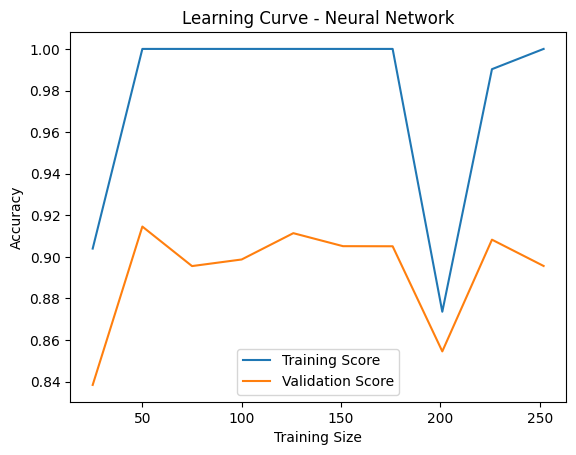

In [ ]:
# Evaluation 2: Learning Curve
train_sizes_nn, train_scores_nn, val_scores_nn = learning_curve(
    nn_untuned_narrow,
    X_train, y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean_nn = train_scores_nn.mean(axis=1)
val_mean_nn = val_scores_nn.mean(axis=1)

plt.plot(train_sizes, train_mean_nn, label='Training Score')
plt.plot(train_sizes, val_mean_nn, label='Validation Score')
plt.legend()
plt.xlabel('Training Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Neural Network')
plt.show()

AUC Score: 0.9758241758241759


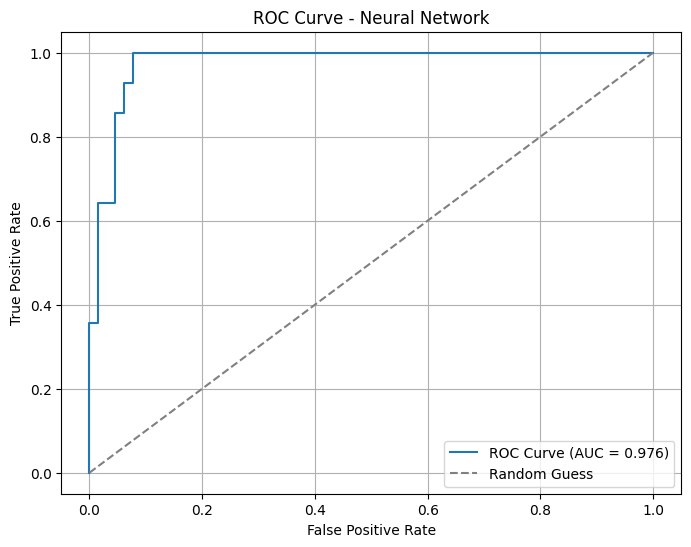

In [ ]:
# Evaluation 3: ROC Curve
y_prob = nn_untuned_narrow.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score_nn = roc_auc_score(y_test, y_prob)
print("AUC Score:", auc_score_nn)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score_nn:.3f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Neural Network")
plt.legend()
plt.grid(True)

Neural Network Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96        65
           1       0.80      0.86      0.83        14

    accuracy                           0.94        79
   macro avg       0.88      0.91      0.89        79
weighted avg       0.94      0.94      0.94        79



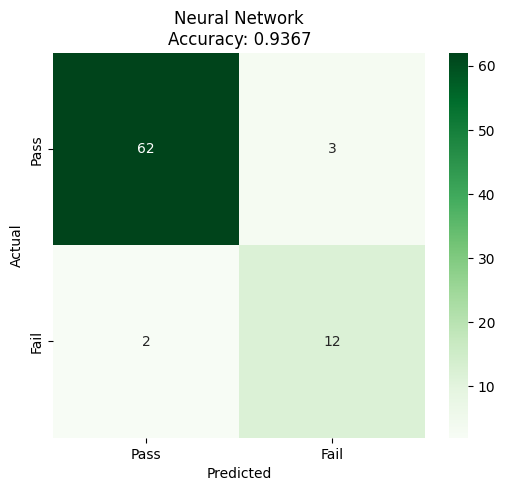

In [ ]:
# Evaluation 4: Confusion Matrix
print("Neural Network Classification Report:")
print(classification_report(y_test, y_pred_untuned_narrow))

cm_nn = confusion_matrix(y_test, y_pred_untuned_narrow)
plt.figure(figsize=(6, 5))
sb.heatmap(cm_nn, annot=True, fmt='d', cmap='Greens',
           xticklabels=['Pass', 'Fail'], yticklabels=['Pass', 'Fail'])
plt.title(f"Neural Network\nAccuracy: {acc_untuned_narrow:.4f}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

## **Build Logistic Regression**

In [ ]:
# Create Baseline Model (LogisticRegression(max_iter=1000, solver='lbfgs', penalty='l2') default
baseline_model = LogisticRegression(max_iter=1000, random_state = 42)


In [ ]:
# Define Hyperparameter Search Space
param_dist_lr = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'penalty': ['l2'],
    'solver': ['lbfgs'],
    'class_weight': [None, 'balanced']
}

##### Hyperparameter Tuning Using Random Search

In [ ]:
random_search_lr = RandomizedSearchCV(
    estimator = baseline_model,
    param_distributions = param_dist_lr,
    n_iter = 10,
    cv = 5,
    scoring = 'f1',
    random_state = 42,
    n_jobs = -1
)

random_search_lr.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=LogisticRegression(max_iter=1000, random_state=42),
                   n_jobs=-1,
                   param_distributions={'C': [0.0001, 0.001, 0.01, 0.1, 1, 10,
                                              100, 1000],
                                        'class_weight': [None, 'balanced'],
                                        'penalty': ['l2'],
                                        'solver': ['lbfgs']},
                   random_state=42, scoring='f1')

In [ ]:
print("Logistic Regression Best Parameters: ", random_search_lr.best_params_)
print("Logistic Regression Best CV F1 Score: ", random_search_lr.best_score_)

Logistic Regression Best Parameters:  {'solver': 'lbfgs', 'penalty': 'l2', 'class_weight': None, 'C': 1}
Logistic Regression Best CV F1 Score:  0.7512692138779095


##### Train and predict using both models

In [ ]:
# Train baseline lr model
start_lr = time.time()
lr = LogisticRegression(max_iter=1000, random_state = 42)
lr.fit(X_train, y_train)
end_lr = time.time()

train_time_lr = end_lr - start_lr
print("Train Time for Baseline LR:", train_time_lr)

y_pred_lr = lr.predict(X_test)

Train Time for Baseline LR: 0.022490501403808594


In [ ]:
# Train lr model using best parameters
start_lr_bp = time.time()
lr_bp = LogisticRegression(**random_search_lr.best_params_, max_iter=2000, random_state = 42)
lr_bp.fit(X_train, y_train)
end_lr_bp = time.time()

train_time_lr_bp = end_lr_bp - start_lr_bp
print("Train Time for Best Params LR:", train_time_lr_bp)

y_pred_lr_bp = lr_bp.predict(X_test)

Train Time for Best Params LR: 0.026890993118286133


In [ ]:
# Baseline model scores
acc_base_lr = accuracy_score(y_test, y_pred_lr)
prec_base_lr = precision_score(y_test, y_pred_lr)
recall_base_lr = recall_score(y_test, y_pred_lr)
f1_base_lr = f1_score(y_test, y_pred_lr)

# Best parameters model scores
acc_bp_lr = accuracy_score(y_test, y_pred_lr_bp)
prec_bp_lr = precision_score(y_test, y_pred_lr_bp)
recall_bp_lr = recall_score(y_test, y_pred_lr_bp)
f1_bp_lr = f1_score(y_test, y_pred_lr_bp)

comparison_df_lr = pd.DataFrame({
    "Model": ["Baseline LR", "Best Params LR"],
    "Accuracy": [acc_base_lr, acc_bp_lr],
    "Precision": [prec_base_lr, prec_bp_lr],
    "Recall": [recall_base_lr, recall_bp_lr],
    "F1-Score": [f1_base_lr, f1_bp_lr]
})

print(comparison_df_lr)

            Model  Accuracy  Precision    Recall  F1-Score
0     Baseline LR  0.936709   0.846154  0.785714  0.814815
1  Best Params LR  0.936709   0.846154  0.785714  0.814815


##### Evaluate Best Model

In [ ]:
# Evaluation 1: Train-Test Accuracy
train_pred = lr.predict(X_train)
test_pred = lr.predict(X_test)
train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)
#### good fit, the accuracy just a slight difference (well generalise)

Train Accuracy: 0.9525316455696202
Test Accuracy: 0.9367088607594937


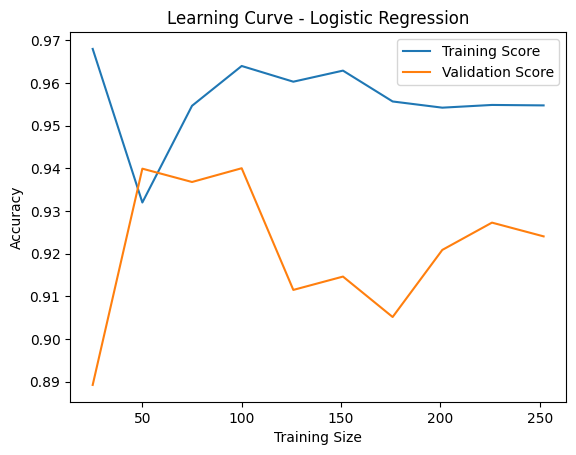

In [ ]:
# Evaluation 2: Learning Curve
train_sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(max_iter=1000),
    X_train, y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.plot(train_sizes, train_mean, label='Training Score')
plt.plot(train_sizes, val_mean, label='Validation Score')
plt.legend()
plt.xlabel('Training Size')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Logistic Regression')
plt.show()

AUC Score: 0.9791208791208791


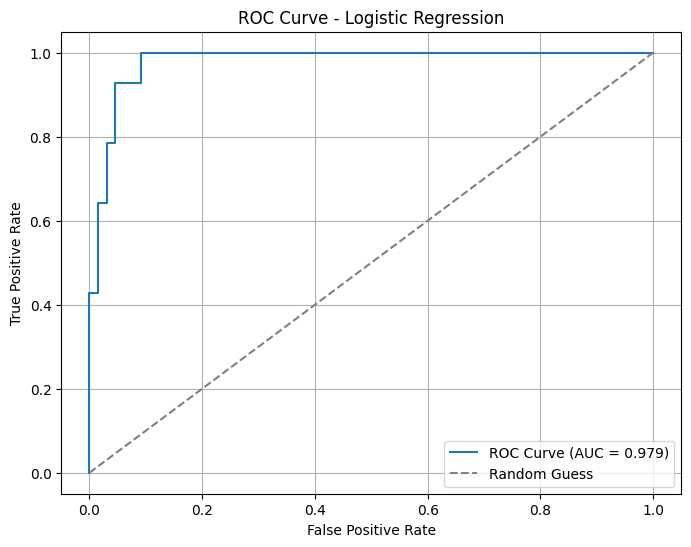

In [ ]:
# Evaluation 3: ROC Curve
y_prob = lr.predict_proba(X_test)[:, 1]  # probability of class fail
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
print("AUC Score:", auc_score)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96        65
           1       0.85      0.79      0.81        14

    accuracy                           0.94        79
   macro avg       0.90      0.88      0.89        79
weighted avg       0.94      0.94      0.94        79



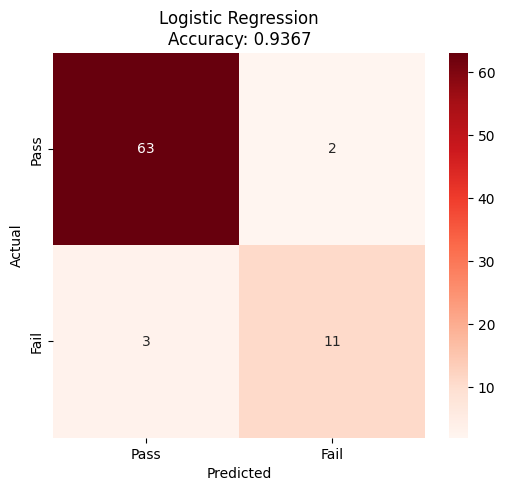

In [ ]:
# Evaluation 4: Confusion Matrix
print("Logistic Regression Classification Report:")
print(classification_report(y_test, test_pred))

cm_lr = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(6, 5))
sb.heatmap(cm_lr, annot=True, fmt='d', cmap='Reds',
           xticklabels=['Pass', 'Fail'], yticklabels=['Pass', 'Fail'])
plt.title(f"Logistic Regression\nAccuracy: {acc_base_lr:.4f}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

## **Final Comparison Between All Models to See Which is the Best**

##### Training Time vs Accuracy Plot


=== Random Forest ===
Accuracy		: 0.9367
Training Time	: 0.0613 seconds

=== XGBoost ===
Accuracy		: 0.9367
Training Time	: 0.0258 seconds

=== SVM ===
Accuracy		: 0.9367
Training Time	: 0.0069 seconds

=== Neural Network ===
Accuracy		: 0.9367
Training Time	: 0.6151 seconds

=== Logistic Regression ===
Accuracy		: 0.9367
Training Time	: 0.0225 seconds


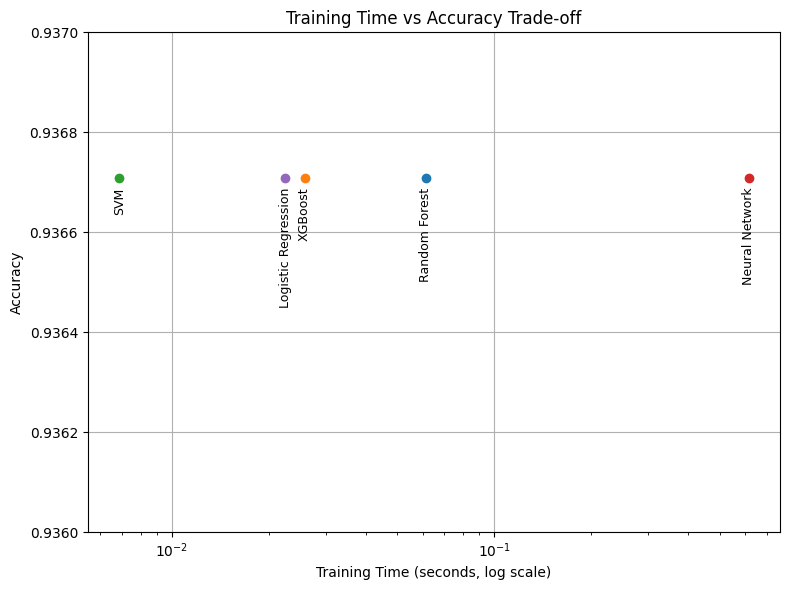

In [ ]:
models = ["Random Forest", "XGBoost", "SVM", "Neural Network", "Logistic Regression"]

accuracies = [acc_base, acc_base_xgb, acc_untuned_poly, acc_untuned_narrow, acc_base_lr]

train_times = [train_time_rf, train_time_xgb, train_time_untuned, train_time_narrow, train_time_lr]

for i in range(len(accuracies)):
  print(f"\n=== {models[i]} ===")
  print(f"Accuracy\t\t: {accuracies[i]:.4f}")
  print(f"Training Time\t: {train_times[i]:.4f} seconds")

plt.figure(figsize=(8,6))

for name, x, y in zip(models, train_times, accuracies):
    plt.scatter(x, y)
    plt.text(
        x, y - 0.00002,   # adjust vertical offset if needed
        name,
        ha='center', va='top',
        fontsize=9,
        rotation=90     # vertical text
    )

plt.xlabel("Training Time (seconds, log scale)")
plt.ylabel("Accuracy")
plt.title("Training Time vs Accuracy Trade-off")
plt.xscale("log")
plt.grid(True)

plt.ylim(0.936, 0.937)

plt.tight_layout()
plt.show()